# Panel B: does base-model variety predict which coding tasks random pushes can move?

**Artifact `art_9a8LrIv2lHbV`** is the iteration-5 confirmation of Claims **A1/A2** on **Qwen3-8B** (instruct, revision `b968826d`) vs **Qwen3-8B-Base** (revision `49e3418f`), panel B of two. It uses a bf16 HF engine on one RTX 4090, identical chat-templated token ids for both models, the exp8 inverse-CDF common-random-number (CRN) sampler, and thinking off.

**The question, in plain terms.** Ask an instruct LLM to solve a coding task and it nearly always writes the *same* algorithm, its **default**. For "find the missing number" that is `n*(n+1)//2 - sum(nums)`. Can a nudge to its internal activations push it onto a *different* correct algorithm? Can we tell in advance *which* tasks will move, and *where* they land? The bet tested here: look at the **base** model. Suppose the pre-trained base model, given the identical prompt, already writes several different correct algorithms. Then the instruct default is a learned preference on top of a varied repertoire, and random pushes should tip it back into that repertoire.

| quantity (per coding unit *u*) | meaning |
|---|---|
| default | the instruct model's modal correct mechanism under 5 neutral "twin" prompts (N = 50), if its share is at least 0.6 |
| `beta_u` (**predictor, ours**) | share of the base model's **correct** programs whose mechanism differs from the default (N = 200 base samples) |
| `r_u` (**predicted landing**) | the base model's most frequent correct non-default mechanism |
| push | `h_S <- h_S + (alpha*n[l,p] - (h_S - h_twin).u) u` at blocks 12-23, task-spec positions, prefill only; `u` = one of 8 isotropic random directions; alpha in {1, 2}; `n[l,p] = r_Q(l)*||h_twin[l,p]||` |
| escape | stage 1 (N = 10): off-default share >= twin + 0.20 and pass rate >= 0.8 x twin; **confirmed** at N = 30 with one-sided exact binomial p < 0.05 |
| `E_u` (**outcome**) | escape fraction = mean over alpha of (confirmed directions / 8) |

- **A1:** does `beta_u` rank `E_u` across units? (Spearman rho, exact one-sided permutation p)
- **A2:** for units that move, does `r_u` name the push landing? Does the base composition forecast the landing better than association answers (ASSOC) and AST proximity (PROX)?

`beta_u`, `r_u` and every rival predictor were sha256 hash-chained **before** the unit's first push sample.

**What this notebook runs.** `method.py` orchestrates ten stages. The GPU stages sampled 14,600 programs from the two 8B models (1.74 GPU-hours) and labelled them with sandboxed runtime tracers, AST rules and LLM judges; they are not re-run here. The notebook re-runs the scientific core of the CPU-only `final` stage **inline, with the original code**, on the frozen labelled programs:

1. **Commit stage, re-derived** (`src/quantities.py`): default, `beta_u`, `r_u`, Hill-1, coverage, bootstrap class probability, R_modal / R_novel and the BASE/ASSOC forecasts, computed from the labelled twin/base programs and checked against the committed records.
2. **Escape rule** (`src/labels_view.py`): two-stage exact-binomial confirmation, giving `E_u`.
3. **A1/A2** (`analysis/a1a2.py`): Spearman, exact permutation p, bootstrap CI, rivals, sensitivities, placebo, Poisson-binomial top-1, log scores.
4. **Within-parent variants** (`analysis/variants.py`) and **extended A1 views** (`analysis/a1_extended.py`).

The data file `mini_demo_data.json` holds one example per unit: the 7 new units B1-B7, 8 parent re-measures `P_<t>` and 8 disguised variants `V_<t>`. Each example carries its committed prediction record and its labelled program rows (10,000 rows in all, about 0.7 MB).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab (method.py logs with it), always install
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py
import argparse
import subprocess
import sys
from pathlib import Path

from loguru import logger

# --- src/cfg5.py, src/labels_view.py, src/quantities.py, analysis/a1a2.py, analysis/variants.py, analysis/a1_extended.py
import csv
import hashlib
import itertools
import json
import math
import time
from collections import Counter, defaultdict
from datetime import datetime, timezone
from typing import Any

import numpy as np
from scipy import stats
from scipy.stats import binomtest

# --- notebook additions (in-memory csv, tables, figures)
import io
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-5/experiment-26/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# An older demo file in another format can still be served at the same URL (raw.githubusercontent.com also caches for
# minutes after a push); use the local copy when the loaded file lacks this notebook's per-program rows.
if "row_columns" not in data.get("metadata", {}) and Path("mini_demo_data.json").exists():
    print("GitHub copy is in a different format; using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
_ex = data["datasets"][0]["examples"]
print(f"{len(_ex)} units:", ", ".join(e["metadata_unit"] for e in _ex))
print(f"{data['metadata']['n_rows']} labelled program rows; columns {data['metadata']['row_columns']}")

GitHub copy is in a different format; using local mini_demo_data.json
23 units: B1, B2, B3, B4, B5, B6, B7, P_T03, V_T03, P_T10, V_T10, P_T05, V_T05, P_T06, V_T06, P_T04, V_T04, P_T08, V_T08, P_T14, V_T14, P_R1, V_R1
10000 labelled program rows; columns ['template', 'arm', 'slot', 'model_tag', 'family', 'label', 'passed', 'sublabel']


## Configuration

These are all the loop sizes of the analysis. The scripts hard-code them, either as default arguments or as `range(...)` counts; the notebook routes them through the variables below. Only the bootstrap CIs, the placebo, the rarefied Hill-1 values and the shuffled p-values (n > 9) depend on them. Everything else (rho, the exact permutation p for n <= 9, `beta_u`, `r_u`, `E_u`, A2) is exact at any setting.

At the **original values** (in the comments), every number below, including the random-number-dependent ones, reproduces the published result exactly, because the notebook re-creates each script's seeded RNG. At those values the whole analysis takes well under a minute on a CPU. If you change a value, re-run the cells from here down: the functions read these as default arguments when they are defined.

In [5]:
N_SHUFFLE = 10000          # analysis/a1a2.py perm_p: random shuffles when n > 9 (exact enumeration otherwise)  (original: 10000)
N_BOOT = 10000             # analysis/a1a2.py boot_ci: unit-bootstrap resamples for the 95% CI of rho             (original: 10000)
N_BOOT_RIVAL = 10000       # analysis/a1a2.py a1(): paired bootstrap of rho(beta, E) - rho(rival, E)            (original: 10000)
N_PLACEBO = 1000           # analysis/a1a2.py a1(): shuffled-beta placebo repetitions                           (original: 1000)
RAREFY_DEPTH = 25          # Hill-1 rarefaction depth (a1a2.rarefied, quantities.rarefied_hill)                  (original: 25)
RAREFY_N_SUB = 1000        # rarefaction subsamples                                                             (original: 1000)
N_BOOT_BETA = 2000         # src/quantities.py boot_beta: resamples for P(beta >= 0.05), P(beta >= 0.2)          (original: 2000)
N_SHUFFLE_CLUSTER = 10000  # analysis/a1_extended.py clustered_p: cluster-preserving shuffles                   (original: 10000)

## 1. The orchestrator: `method.py`

`method.py` holds no analysis itself. It runs each stage's scripts as subprocesses on the full repository, as listed in its docstring. The cell below is the original file with three changes: its docstring is assigned to `__doc__`, `ROOT` is the current folder (a notebook has no `__file__`), and the debug log file is not written. `main()` is defined but **not called**: every stage needs `src/`, `analysis/` and `data/` on disk, and the GPU stages need both 8B models. The following sections run the core of the `final` stage inline instead.

In [6]:
__doc__ = """Panel B of the iteration-5 confirmation (Claims A1/A2) on Qwen3-8B (instruct) and Qwen3-8B-Base.

METHOD (ours): a ban-free, base-derived predictor of push movability. For every coding unit, the base model's
repertoire under the identical chat-templated prompt gives beta_u (share of correct base programs whose mechanism is
not the instruct twin's default) and r_u (the base model's most frequent correct non-default mechanism). Both are
hash-committed BEFORE the unit's first push sample. A1: does beta_u rank the escape fraction E_u of isotropic random
pushes (8 directions x alpha 1, 2; task-spec positions, blocks 12-23, prefill only) across units? A2: does r_u (and
the base composition) forecast where the pushes land?
BASELINES / RIVALS (same frozen material, committed beside beta): R_modal (1 - twin modal share), R_margin (opening
log-prob margin of the default over the best survivor), R_merit (runtime and length of the fastest non-default
reference vs the default's), R_novel (novelty-instruction off-default share), K_u (catalogue size) for A1; ASSOC
(association answers) and PROX (AST proximity) forecasts against BASE for A2; plus shuffled-beta, shuffled-arm and
twin-as-push placebos.

This file orchestrates the stages implemented in src/ (see README.md for the full layout):
  setup     extract dependency rows, render prompts, commit #0           (src/extract_sources.py, src/protocol0.py)
  build     unit build + gate stage (i) for B1-B7                         (src/unitbuild.py)
  gpu-i1    instruct: GPU tests, engine check, twins/novelty/association  (src/gpu_main.py)
  gpu-b1    base: chat repertoire (N = 200) + plain completion            (src/gpu_main.py)
  label     CPU label worker (runtime primary, AST second, judges on disagreement)   (src/label5.py)
  gate      gate stage (ii) (+ one revision round)                        (src/gate2.py)
  commit    per-unit predictions + hash chain                             (src/quantities.py, src/quantities_extra.py)
  push      escape population, confirmations, PN, T1.3                     (src/gpu_main.py --phases push)
  extra     disguised variants + paired parents                           (src/units_extra.py, gpu phases extra_*)
  final     analysis, audits, figures and outputs (CPU only; this is what `uv run method.py` runs by default)
"""

ROOT = Path.cwd()  # notebook: was Path(__file__).resolve().parent (a notebook has no __file__)
PY = sys.executable
UNITS = "B1,B2,B3,B4,B5,B6,B7"
PAIRS = "T03,T10,T05,T06,T04,T08,T14,R1"

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
# notebook: the original also writes a DEBUG log file; disabled so that the notebook writes no files
# (ROOT / "logs").mkdir(exist_ok=True)
# logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")


def run(args: list[str], cwd: Path | None = None) -> None:
    logger.info(f"$ {' '.join(args)}")
    r = subprocess.run([PY] + args, cwd=str(cwd or ROOT))
    if r.returncode != 0:
        raise RuntimeError(f"stage failed ({r.returncode}): {' '.join(args)}")


STAGES = {
    "setup": [["src/extract_sources.py"], ["src/protocol0.py"]],
    "build": [["src/unitbuild.py", UNITS]],
    "gpu-i1": [["src/gpu_main.py", "--model", "instruct", "--phases", "tests,engine,inst1,margins", "--units", UNITS]],
    "gpu-b1": [["src/gpu_main.py", "--model", "base", "--phases", "base1", "--units", UNITS, "--n-base", "40"]],
    "label": [["src/label5.py", "--once"]],
    "gate": [["src/gate2.py", UNITS]],
    "commit": [["src/quantities.py", UNITS]],
    "push": [["src/gpu_main.py", "--model", "instruct", "--phases", "push", "--units", UNITS]],
    "extra": [["src/units_extra.py"],
              ["src/gpu_main.py", "--model", "instruct", "--phases", "extra_inst", "--pairs", PAIRS],
              ["src/gpu_main.py", "--model", "base", "--phases", "extra_base", "--pairs", PAIRS],
              ["src/quantities_extra.py", ",".join(f"{p}{t}" for t in PAIRS.split(",") for p in ("P_", "V_"))],
              ["src/gpu_main.py", "--model", "instruct", "--phases", "push", "--arms", "esc,conf", "--units",
               ",".join(f"{p}{t}" for t in PAIRS.split(",") for p in ("P_", "V_"))]],
    "final": [["src/adjudicate_all.py"], ["src/engine_check.py"], ["analysis/a1a2.py"], ["analysis/variants.py"], ["analysis/a1_extended.py"],
              ["analysis/screen_view.py"], ["src/novelty_audit.py"], ["audit/rederive.py"], ["audit/commit_order.py"], ["tests/test_analysis.py"],
              ["tests/test_cpu.py"], ["tests/test_datasets.py"], ["src/vendor_check.py"], ["src/figures.py"], ["src/outputs.py"]],
}


@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__.split("\n")[0])
    ap.add_argument("--stage", default="final", help="comma-separated stages, or 'all'; see the module docstring")
    a = ap.parse_args()
    order = list(STAGES) if a.stage == "all" else a.stage.split(",")
    for s in order:
        if s not in STAGES:
            raise ValueError(f"unknown stage {s}; choose from {list(STAGES)}")
        logger.info(f"=== stage {s}")
        for cmd in STAGES[s]:
            run(cmd)
    logger.info("done")


# if __name__ == "__main__":
#     main()   # notebook: not called -- every stage is a subprocess on the full repository (and GPU stages need the
#              # two 8B models); the cells below run the core of the `final` stage inline instead

In [7]:
# The ten stages and what they need; this notebook re-runs the analysis core of `final` (marked *) inline.
_needs = {"setup": "CPU", "build": "CPU", "gpu-i1": "GPU, Qwen3-8B", "gpu-b1": "GPU, Qwen3-8B-Base",
          "label": "CPU + LLM judges", "gate": "CPU + LLM judges", "commit": "CPU + LLM judges + gpu-i1 margins",
          "push": "GPU, Qwen3-8B", "extra": "GPU, both models", "final": "CPU"}
_inline = {"analysis/a1a2.py", "analysis/variants.py", "analysis/a1_extended.py", "src/quantities.py"}
for s, cmds in STAGES.items():
    print(f"{s:7s} [{_needs[s]}]")
    for c in cmds:
        print(f"   {'*' if c[0] in _inline else ' '} python {' '.join(c)}")

setup   [CPU]
     python src/extract_sources.py
     python src/protocol0.py
build   [CPU]
     python src/unitbuild.py B1,B2,B3,B4,B5,B6,B7
gpu-i1  [GPU, Qwen3-8B]
     python src/gpu_main.py --model instruct --phases tests,engine,inst1,margins --units B1,B2,B3,B4,B5,B6,B7
gpu-b1  [GPU, Qwen3-8B-Base]
     python src/gpu_main.py --model base --phases base1 --units B1,B2,B3,B4,B5,B6,B7 --n-base 40
label   [CPU + LLM judges]
     python src/label5.py --once
gate    [CPU + LLM judges]
     python src/gate2.py B1,B2,B3,B4,B5,B6,B7
commit  [CPU + LLM judges + gpu-i1 margins]
   * python src/quantities.py B1,B2,B3,B4,B5,B6,B7
push    [GPU, Qwen3-8B]
     python src/gpu_main.py --model instruct --phases push --units B1,B2,B3,B4,B5,B6,B7
extra   [GPU, both models]
     python src/units_extra.py
     python src/gpu_main.py --model instruct --phases extra_inst --pairs T03,T10,T05,T06,T04,T08,T14,R1
     python src/gpu_main.py --model base --phases extra_base --pairs T03,T10,T05,T06,T04,T08,T14

## 2. Frozen design constants (`src/cfg5.py`)

This is the subset of the constants module that the analysis uses: the two pinned models, the five twin templates W1-W5, and the design numbers frozen in commit #0. Those are the push strengths `ALPHAS`, the number of isotropic directions `N_DIRS`, the escape thresholds `ESC_EXCESS` / `ESC_PASS_FRAC`, the default-share threshold, and `K`, the CRN slot ranges per arm. Each template is rendered with **5 slots per template**, so `K["twin"] = range(10)` means 5 x 10 = 50 twin samples. `direction_seed` is the sha256 rule that fixes the 8 push directions of each unit. A variant `V_<t>` and its parent `P_<t>` share the parent's seeds, so their pushes are paired.

In [8]:
# ---- src/cfg5.py (excerpt; verbatim)
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
BASE_ID = "Qwen/Qwen3-8B-Base"
BASE_REVISION = "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"   # newest snapshot on 2026-10-21 (pinned here, logged)
N_LAYERS = 36
D_MODEL = 4096
MAX_NEW = 1024
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
PRECISION = "bf16_hf"   # precision rule: cc >= 8.9 and VRAM < 19.5 GiB -> FP8 W8A8; else bf16 (RTX 4090, 24 GiB)
DECODING_STR = "T1.0_topp1.0_topk-off_max1024_thinkoff_fencestop"

TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) -- protocol v2 W1-W5, verbatim (exp17/exp22)
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."
NOVELTY_SEGMENT = "Write a novel algorithm for this task, one you have not seen before."
ASSOCIATION_TEMPLATE = ("What is the standard alternative to {x} for this task? "
                        "Name one algorithm and answer in one sentence.")
FORMAT_LINE = ("Use only the Python standard library. Return only one ```python code block containing the function "
               "solve and any helpers, with no example usage and no explanation.")

EDIT_BLOCKS = list(range(12, 24))
CAP_BLOCKS = list(range(12, 36))
B = 20
ALPHAS = (1.0, 2.0)
N_DIRS = 8
ESC_EXCESS = 0.20
ESC_PASS_FRAC = 0.8
DEFAULT_SHARE = 0.6
K = {"twin": list(range(10)), "esc1": [0, 1], "conf": [2, 3, 4, 5], "base": list(range(20)), "pilot": list(range(6)),
     "pn": list(range(10)), "t13": list(range(10)), "gate": [100, 101], "parent_base": list(range(10))}
N_NOVELTY = 30
N_ASSOC = 20
N_PLAIN = 50
EXCLUDE = ("invalid", "disputed")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def direction_seed(unit: str, k: int) -> int:
    """Plan section 2: seed(unit, k) = int(sha256('iter5|panelB|{unit}|dir|{k}')[:8], 16). Variants V_<t> and their
    paired parent re-measures P_<t> use the PARENT's seeds (keyed on <t>)."""
    if unit[:2] in ("P_", "V_"):
        unit = unit[2:]
    return int(hashlib.sha256(f"iter5|panelB|{unit}|dir|{k}".encode()).hexdigest()[:8], 16)


print("twin prompt W1 (neutral):", TEMPLATES["W1"][1])
print("direction seeds of B2:   ", [direction_seed("B2", k) for k in range(N_DIRS)])

twin prompt W1 (neutral): Do not use {N} for this task.
direction seeds of B2:    [4220267686, 1167779660, 2488292451, 3394732635, 1031373525, 601733224, 3249191917, 1268461828]


## 3. Data access: file readers replaced by the loaded `data`

The scripts read their inputs from files on disk:
- `predictions/units/<u>.json`, the committed predictions;
- `units/<u>/catalogue_frozen.json` and `units/<u>/default.json`;
- the labelled program table, through `labels_view.final_rows(u)`, which joins `data/labels.jsonl`, `data/judge_labels.jsonl` and `data/samples_raw.jsonl`.

Here those readers return the same objects from `mini_demo_data.json`.

Each row is one sampled program: `model_tag` (instruct/base), `arm` (TWIN, BASE, PLAIN, NOV, ESC_d<seed>_a<alpha>, PN_a<alpha>, T13), CRN `template`/`slot`, the **final mechanism label**, and whether it **passed** the hidden tests. The final label is the runtime/AST labeller's label when they agree, otherwise the blind-judge adjudication, otherwise `disputed`; labels outside the frozen catalogue become `other`. Rows of the `*_EXTRA` and `GATE` arms are not included, because no analysis filter selects them. Results that the scripts write to `results/*.json` are kept in the in-memory dict `RESULTS` instead.

In [9]:
# notebook: the original reads these from files on disk; here they come from `data` (mini_demo_data.json)
ROW_COLUMNS = data["metadata"]["row_columns"]
UNIT_DATA = {ex["metadata_unit"]: ex for ex in data["datasets"][0]["examples"]}

RESULTS: dict[str, Any] = {}      # in-memory stand-in for the results/ folder
RESULTS_DIR = Path("results")


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    """notebook: src/cfg5.write_json writes results/<name>; here the object is kept in RESULTS[<name>]."""
    RESULTS[Path(p).name] = obj


def frozen_catalogue(u: str) -> list[str]:
    """notebook: was read_json(UNITS_DIR / u / "catalogue_frozen.json")["catalogue"]."""
    return UNIT_DATA[u]["metadata_catalogue_frozen"]


def default_of(u: str) -> str | None:
    """notebook: was read_json(UNITS_DIR / u / "default.json")["default"]."""
    return UNIT_DATA[u]["metadata_default"]["default"]


def final_rows(u: str | None = None) -> list[dict[str, Any]]:
    """notebook: the rows src/labels_view.final_rows(u) returns, precomputed (by the original function) and stored in
    mini_demo_data.json with the columns the analysis reads."""
    out = []
    for uu in ([u] if u is not None else list(UNIT_DATA)):
        for vals in UNIT_DATA[uu]["metadata_rows"]:
            r = dict(zip(ROW_COLUMNS, vals))
            r["unit"] = uu
            r["key"] = f"{uu}|{r['template']}|{r['arm']}|{r['slot']}|{r['model_tag']}"
            out.append(r)
    return out


_all = pd.DataFrame(final_rows())
print(pd.crosstab(_all["unit"], _all["family"]).to_string())
_all[_all["unit"] == "B2"].groupby(["arm", "model_tag"], sort=False).head(1).head(8)

family  BASE  ESC  NOV  PLAIN   PN  T13  TWIN
unit                                         
B1       200  160   30     50  100   50    50
B2       200  300   30     50  100   50    50
B3       200  200   30     50  100   50    50
B4       200  200   30     50  100   50    50
B5       200  160   30     50  100   50    50
B6       200  160   30     50  100   50    50
B7       200  260   30     50  100   50    50
P_R1      50  160    0      0    0    0    50
P_T03     50  360    0      0    0    0    50
P_T04     50  160    0      0    0    0    50
P_T05     50  160    0      0    0    0    50
P_T06     50  160    0      0    0    0    50
P_T08     50  160    0      0    0    0    50
P_T10     50  240    0      0    0    0    50
P_T14     50  160    0      0    0    0    50
V_R1     100  160    0      0    0    0    50
V_T03    100  400    0      0    0    0    50
V_T04    100  160    0      0    0    0    50
V_T05    100  160    0      0    0    0    50
V_T06    100  160    0      0    0

,template,arm,slot,model_tag,family,label,passed,sublabel,unit,key
640,W1,TWIN,0,instruct,TWIN,hash_count,True,hash_count/count,B2,B2|W1|TWIN|0|instruct
690,W1,BASE,0,base,BASE,invalid,False,None,B2,B2|W1|BASE|0|base
790,NOV,NOV,0,instruct,NOV,hash_count,True,hash_count/toggle,B2,B2|NOV|NOV|0|instruct
820,PLAIN,PLAIN,0,base,PLAIN,xor_fold,False,hash_count/count,B2,B2|PLAIN|PLAIN|0|base
970,W1,ESC_d4220267686_a1.0,0,instruct,ESC,xor_fold,True,hash_count/count,B2,B2|W1|ESC_d4220267686_a1.0|0|instruct
972,W1,ESC_d1167779660_a1.0,0,instruct,ESC,xor_fold,True,hash_count/count,B2,B2|W1|ESC_d1167779660_a1.0|0|instruct
974,W1,ESC_d2488292451_a1.0,0,instruct,ESC,xor_fold,True,hash_count/count,B2,B2|W1|ESC_d2488292451_a1.0|0|instruct
976,W1,ESC_d3394732635_a1.0,0,instruct,ESC,hash_count,True,hash_count/count,B2,B2|W1|ESC_d3394732635_a1.0|0|instruct


## 4. Final labels and the escape rule (`src/labels_view.py`)

`summarise` turns a set of programs into an **off-default share**: catalogue labels other than the default, over valid attempts, with `invalid` and `disputed` excluded. It also gives a **pass rate** (passed / all attempts). `direction_table` applies the frozen exp22 escape rule to each of the 16 push cells of a unit (8 directions x 2 alphas), against the unit's twin cell:

- **stage 1** (CRN slots 0-1, N = 10): off-default share >= twin share + 0.20, and pass >= 0.8 x twin pass;
- **confirmation** (slots 0-5 pooled, N = 30): the excess still >= 0.20, a one-sided exact binomial p < 0.05 against `p0 = (k_twin + 0.5)/(n_twin + 1)`, and the pass rate holds.

`E_u` is the mean over the two alphas of the fraction of the 8 directions that confirm. The **push landing** is the most frequent correct off-default mechanism, pooled over the confirmed cells.

In [10]:
# ---- src/labels_view.py (verbatim; file readers in section 3)
EXCLUDE = ("invalid", "disputed")


def summarise(rows: list[dict[str, Any]], cat: set[str], d: str | None) -> dict[str, Any]:
    valid = [r for r in rows if r["label"] not in EXCLUDE]
    off = [r for r in valid if r["label"] in cat and r["label"] != d]
    corr = [r for r in rows if r["passed"]]
    n = len(valid)
    return {"n_rows": len(rows), "n_valid": n, "off_default": len(off), "share": len(off) / n if n else None,
            "pass": len(corr) / len(rows) if rows else None, "n_correct": len(corr),
            "labels_attempted": dict(Counter(r["label"] for r in rows)),
            "labels_correct": dict(Counter(r["label"] for r in corr)),
            "landing_correct": dict(Counter(r["label"] for r in corr if r["label"] in cat and r["label"] != d))}


def twin_summary(rows: list[dict[str, Any]], cat: set[str], d: str | None) -> dict[str, Any]:
    tw = [r for r in rows if r["arm"] == "TWIN" and r["model_tag"] == "instruct" and r["slot"] in K["twin"]]
    return summarise(tw, cat, d)


def direction_table(u: str, rows: list[dict[str, Any]] | None = None, seeds: list[int] | None = None,
                    d: str | None = None) -> dict[str, Any]:
    rows = rows if rows is not None else final_rows(u)
    d = d or default_of(u)
    cat = set(frozen_catalogue(u))
    tw = twin_summary(rows, cat, d)
    k_tw, n_tw = tw["off_default"], tw["n_valid"]
    p0 = (k_tw + 0.5) / (n_tw + 1)
    seeds = seeds or [direction_seed(u, k) for k in range(N_DIRS)]
    by: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for r in rows:
        if r["family"] == "ESC":
            by[r["arm"]].append(r)
    tab: dict[str, Any] = {"twin": tw, "p0": p0, "cells": {}}
    for a in ALPHAS:
        for s in seeds:
            arm = f"ESC_d{s}_a{a}"
            rr = by.get(arm, [])
            s1 = [r for r in rr if r["slot"] in K["esc1"]]
            s30 = [r for r in rr if r["slot"] in K["esc1"] + K["conf"]]
            S1 = summarise(s1, cat, d)
            S30 = summarise(s30, cat, d)
            st1 = (S1["share"] is not None and tw["share"] is not None and len(s1) >= 10 and
                   S1["share"] - tw["share"] >= ESC_EXCESS - 1e-12 and S1["pass"] >= ESC_PASS_FRAC * tw["pass"] - 1e-12)
            conf, pval = False, None
            if st1 and len(s30) >= 30 and S30["n_valid"] > 0:
                pval = float(binomtest(S30["off_default"], S30["n_valid"], p0, alternative="greater").pvalue)
                conf = (S30["share"] - tw["share"] >= ESC_EXCESS - 1e-12 and pval < 0.05 and
                        S30["pass"] >= ESC_PASS_FRAC * tw["pass"] - 1e-12)
            tab["cells"][arm] = {"seed": s, "alpha": a, "stage1": S1, "stage1_pass": st1, "n_rows": len(rr),
                                 "pooled30": S30 if len(s30) >= 30 else None, "confirmed": conf, "p": pval,
                                 "excess_stage1": None if S1["share"] is None else S1["share"] - (tw["share"] or 0),
                                 "excess_pooled": None if len(s30) < 30 or S30["share"] is None else
                                 S30["share"] - (tw["share"] or 0),
                                 "needs_confirmation": st1 and len(s30) < 30}
    E = {}
    for a in ALPHAS:
        cells = [c for c in tab["cells"].values() if c["alpha"] == a]
        E[str(a)] = sum(c["confirmed"] for c in cells) / len(seeds)
    tab["E_by_alpha"] = E
    tab["E_u"] = sum(E.values()) / len(E)
    tab["movable"] = tab["E_u"] > 0
    land = Counter()
    for c in tab["cells"].values():
        if c["confirmed"]:
            for lab, n in c["pooled30"]["landing_correct"].items():
                land[lab] += n
    tab["push_landing_composition"] = dict(land)
    tab["push_landing"] = land.most_common(1)[0][0] if land else None
    if land and len(land) > 1:
        top = land.most_common(2)
        if top[0][1] == top[1][1]:
            tab["push_landing_tie"] = [k for k, v in land.items() if v == top[0][1]]
    return tab

Here is the rule applied to **B2 (single number)**. The instruct default is `hash_count`, a counter of occurrences; the alternative `xor_fold` folds XOR over the list. Some directions flip almost every sample to `xor_fold`, while others do nothing:

In [11]:
_tab = direction_table("B2")
print(f"B2 twin: off-default share {_tab['twin']['share']:.2f}, pass {_tab['twin']['pass']:.2f}; "
      f"binomial null p0 = {_tab['p0']:.3f}")
print(f"E by alpha = {_tab['E_by_alpha']}, E_u = {_tab['E_u']:.4f}, push landing = {_tab['push_landing']} "
      f"{_tab['push_landing_composition']}")
pd.DataFrame([{"arm": arm, "stage-1 share (N=10)": c["stage1"]["share"], "stage-1 pass": c["stage1"]["pass"],
               "stage 1 passed": c["stage1_pass"], "pooled share (N=30)": (c["pooled30"] or {}).get("share"),
               "exact binomial p": c["p"], "confirmed": c["confirmed"]} for arm, c in _tab["cells"].items()])

B2 twin: off-default share 0.08, pass 1.00; binomial null p0 = 0.088
E by alpha = {'1.0': 0.375, '2.0': 0.5}, E_u = 0.4375, push landing = xor_fold {'xor_fold': 160}


,arm,stage-1 share (N=10),stage-1 pass,stage 1 passed,pooled share (N=30),exact binomial p,confirmed
0,ESC_d4220267686_a1.0,1.0,1.0,True,0.933333,1.094305e-27,True
1,ESC_d1167779660_a1.0,0.1,1.0,False,NaN,NaN,False
2,ESC_d2488292451_a1.0,0.4,1.0,True,0.533333,5.847209e-10,True
3,ESC_d3394732635_a1.0,0.0,1.0,False,NaN,NaN,False
4,ESC_d1031373525_a1.0,0.0,1.0,False,NaN,NaN,False
5,ESC_d601733224_a1.0,0.4,1.0,True,0.466667,6.403210e-08,True
6,ESC_d3249191917_a1.0,0.0,1.0,False,NaN,NaN,False
7,ESC_d1268461828_a1.0,0.0,1.0,False,NaN,NaN,False
8,ESC_d4220267686_a2.0,1.0,1.0,True,0.966667,7.278309e-30,True
9,ESC_d1167779660_a2.0,0.7,1.0,True,0.633333,1.935966e-13,True


## 5. The predictor: per-unit quantities of the commit stage (`src/quantities.py`)

This is where **`beta_u`** and **`r_u`** come from. `compute_unit` first takes the default: the modal correct twin mechanism if its share is >= 0.6. Then, from the base model's 200 chat-templated samples (`BASE`, slots 0-39), it computes:
- `beta_u`, the share of correct base programs that are not the default; if fewer than 20 base programs are correct, the attempt composition is used and the unit is flagged;
- `r_u`, the most frequent correct non-default catalogue mechanism;
- Hill-1 diversity, Good's coverage, and the bootstrap probability that `beta_u >= 0.05`;
- the rivals R_modal (1 - twin modal share) and R_novel (off-default share under "Write a novel algorithm for this task...");
- the BASE / ASSOC landing forecasts (0.93 x raw + 0.05 uniform + 0.02 "other").

**Notebook changes.** Four inputs need the GPU, the unit build or the LLM judges, so they come from the committed record:
- R_margin (teacher-forced log-probs of the instruct model);
- R_merit (reference runtimes on the hidden tests, and reference lengths);
- PROX (zss tree-edit distances between twin programs and the references);
- the association answers mapped to mechanisms, which enter as committed counts and go through the same `smooth()`.

The blind-judge base audit and the banned-word grep audit are not re-run, and nothing is written to disk. Everything else is the original code. The comparison below checks each recomputed value against the hash-committed one.

In [12]:
# ---- src/quantities.py (verbatim helpers; compute_unit with the notebook changes marked)
BASE_SLOTS = set(range(40))
RNG = np.random.default_rng(20261021)


def hill1(labels: list[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return float("nan")
    H = -sum(v / n * math.log(v / n) for v in c.values())
    return math.exp(H)


def rarefied_hill(labels: list[str], depth: int = RAREFY_DEPTH, n_sub: int = RAREFY_N_SUB) -> dict:  # original: 25, 1000
    if len(labels) < depth:
        return {"depth": len(labels), "hill1": hill1(labels), "flag": "fewer_than_depth"}
    arr = np.array(labels)
    vals = [hill1(list(RNG.choice(arr, size=depth, replace=False))) for _ in range(n_sub)]
    return {"depth": depth, "hill1": float(np.mean(vals)), "flag": None}


def goods_coverage(labels: list[str]) -> float | None:
    if not labels:
        return None
    c = Counter(labels)
    return 1.0 - sum(1 for v in c.values() if v == 1) / len(labels)


def boot_beta(labels: list[str], d: str, n_boot: int = N_BOOT_BETA) -> dict:  # original: n_boot = 2000
    if not labels:
        return {"P_beta_ge_0.05": None, "P_beta_ge_0.2": None}
    arr = np.array([l != d for l in labels], dtype=float)
    bs = RNG.choice(arr, size=(n_boot, len(arr)), replace=True).mean(axis=1)
    return {"P_beta_ge_0.05": float((bs >= 0.05).mean()), "P_beta_ge_0.2": float((bs >= 0.2).mean()),
            "ci95": [float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))]}


def smooth(counts: dict[str, float], survivors: list[str], pseudo: float = 0.5) -> dict[str, float]:
    keys = survivors + ["other"]
    raw = {k: counts.get(k, 0.0) + (pseudo if k in survivors else 0.0) for k in keys}
    tot = sum(raw.values())
    p_raw = {k: (v / tot if tot > 0 else 1.0 / len(keys)) for k, v in raw.items()}
    return {k: 0.93 * p_raw[k] + (0.05 / len(survivors) if k in survivors else 0.0) + (0.02 if k == "other" else 0.0)
            for k in keys}


def compute_unit(u: str, do_audit: bool = True) -> dict:
    committed = UNIT_DATA[u]["metadata_prediction"]  # notebook: source of the GPU / judge / unit-build inputs below
    # adjudicate_pending([u])  # notebook: judge adjudication is already applied (the rows carry final labels)
    rows = final_rows(u)
    cat = frozen_catalogue(u)
    catset = set(cat)
    tw = [r for r in rows if r["arm"] == "TWIN" and r["model_tag"] == "instruct" and r["slot"] in range(10)]
    tw_corr = [r["label"] for r in tw if r["passed"] and r["label"] not in EXCLUDE]
    c = Counter(tw_corr)
    modal, mshare = (c.most_common(1)[0][0], c.most_common(1)[0][1] / len(tw_corr)) if tw_corr else (None, 0.0)
    default = modal if (modal in catset and mshare >= DEFAULT_SHARE and len(tw) >= 50) else "NO_DEFAULT"
    flags = []
    if len(tw_corr) < 10:
        flags.append(f"default_from_few_correct(n_correct={len(tw_corr)})")
    twin_pass = sum(r["passed"] for r in tw) / len(tw) if tw else None
    if twin_pass is not None and twin_pass < 0.7:
        flags.append(f"twin_pass_below_0.7({twin_pass:.2f})")
    # write_json(UNITS_DIR / u / "default.json", {...})  # notebook: no file writes
    d = default if default != "NO_DEFAULT" else None
    survivors = [m for m in cat if m != d]
    base = [r for r in rows if r["arm"] == "BASE" and r["model_tag"] == "base" and r["slot"] in BASE_SLOTS]
    b_corr = [r["label"] for r in base if r["passed"] and r["label"] != "disputed"]
    b_att = [r["label"] for r in base if r["label"] not in EXCLUDE]
    plain = [r for r in rows if r["arm"] == "PLAIN"]
    p_corr = [r["label"] for r in plain if r["passed"] and r["label"] != "disputed"]
    beta_correct = (sum(l != d for l in b_corr) / len(b_corr)) if b_corr and d else None
    beta_attempt = (sum(l != d for l in b_att) / len(b_att)) if b_att and d else None
    beta_plain = (sum(l != d for l in p_corr) / len(p_corr)) if p_corr and d else None
    use_attempt = len(b_corr) < 20
    beta = beta_attempt if use_attempt else beta_correct
    if use_attempt:
        flags.append(f"base_fewer_than_20_correct(n={len(b_corr)}): attempt composition used")
    comp_src = b_att if use_attempt else b_corr
    nd = Counter(l for l in comp_src if l in catset and l != d)
    if nd:
        top = nd.most_common()
        ties = [k for k, v in top if v == top[0][1]]
        r_u = ties[0] if len(ties) == 1 else "tie"
    else:
        ties, r_u = [], None
    bb = boot_beta(comp_src, d) if d else {}
    # rivals
    # notebook: R_margin (teacher-forced opening log-probs of the instruct model, results/margins.json from the GPU
    # stage) and R_merit (reference runtimes on units/<u>/tests.jsonl, reference lengths) come from the committed record
    R_margin = committed["rivals"]["R_margin"]
    tot_t = committed["rivals"]["ref_total_runtime_s"]
    R_merit_rt, R_merit_len = committed["rivals"]["R_merit_runtime"], committed["rivals"]["R_merit_length"]
    R_modal = 1.0 - mshare if tw_corr else None
    nov = [r for r in rows if r["arm"] == "NOV" and r["slot"] in range(30)]
    nsum = summarise(nov, catset, d) if d else None
    R_novel = nsum["share"] if nsum else None
    nov_c = [r for r in nov if r["passed"]]
    R_novel_correct = (sum(1 for r in nov_c if r["label"] in catset and r["label"] != d) / len(nov_c)) \
        if (nov_c and d) else None
    # forecasts
    fc = {}
    if d and survivors:
        bc = Counter(l if l in survivors else "other" for l in comp_src if l != d)
        fc["BASE"] = smooth(dict(bc), survivors)
        # notebook: association answers (ASSOC arm, mapped by units_spec.map_answer) enter as the committed counts
        ac = Counter(committed["forecasts"]["ASSOC_raw_counts"])
        fc["ASSOC"] = smooth(dict(ac), survivors)
        fc["ASSOC_raw_counts"] = dict(ac)
        # notebook: PROX (zss tree-edit distance of twin programs to the references, vendor/exp23/prox.py) is committed
        fc["PROX"] = committed["forecasts"]["PROX"]
        fc["PROX_detail"] = committed["forecasts"]["PROX_detail"]
    # audit = base_audit(u, rows, d) if (do_audit and d) else None  # notebook: blind-judge audit not re-run
    # ga = grep_audit(u)                                             # notebook: prompt grep audit not re-run
    rec = {
        "schema": "iter5_panelB_unit_commit_v1", "unit": u, "unit_id": committed["unit_id"], "utc": utc_now(),
        "catalogue": cat, "K_u": len(cat), "excluded_by_limit": committed["excluded_by_limit"],
        "default": default, "flags": flags,
        "twin": {"n": len(tw), "pass": twin_pass, "correct_composition": dict(c),
                 "attempted_composition": dict(Counter(r["label"] for r in tw)), "modal_share": mshare},
        "base": {"n": len(base), "n_correct": len(b_corr), "n_valid_attempts": len(b_att),
                 "correct_composition": dict(Counter(b_corr)), "attempted_composition": dict(Counter(b_att)),
                 "beta_u": beta, "beta_correct": beta_correct, "beta_attempt": beta_attempt, "beta_plain": beta_plain,
                 "beta_source": "attempt" if use_attempt else "correct", "r_u": r_u, "r_u_ties": ties,
                 "hill1_rarefied": rarefied_hill(comp_src) if comp_src else None,
                 "goods_coverage": goods_coverage(comp_src), **bb,
                 "plain": {"n": len(plain), "n_correct": len(p_corr), "correct_composition": dict(Counter(p_corr))}},
        "rivals": {"R_margin": R_margin, "R_merit_runtime": R_merit_rt, "R_merit_length": R_merit_len,
                   "R_modal": R_modal, "R_novel": R_novel, "R_novel_correct": R_novel_correct, "K_u": len(cat),
                   "ref_total_runtime_s": tot_t},
        "novelty_cell": nsum,
        "forecasts": fc,
        "predicted_class": None if beta is None else ("MOVABLE" if beta >= 0.05 else "IMMOVABLE"),
        "predicted_landing": r_u,
    }
    return rec

The mechanism labels are concrete code patterns. Here is one correct program per label for B2: the twin default `hash_count`, the base model's runner-up `xor_fold`, and the rarer `set_sum_identity` (`2*sum(set(nums)) - sum(nums)`):

In [13]:
for _lab, _code in UNIT_DATA["B2"]["metadata_example_programs"].items():
    print(f"----- {_lab}\n{_code.strip()}\n")

----- hash_count
def solve(nums):
    count = {}
    for num in nums:
        if num in count:
            count[num] += 1
        else:
            count[num] = 1
    for key, value in count.items():
        if value == 1:
            return key

----- xor_fold
def solve(nums):
    xor_result = 0
    for num in nums:
        xor_result ^= num
    return xor_result

----- set_sum_identity
def solve(nums):
    return sum(set(nums)) * 2 - sum(nums)

----- sort_pair_scan
def solve(nums):
    """Task: write a Python function solve(nums) that returns the value that occurs exactly once in nums. The argument nums is a list of integers with 1 <= len(nums) <= 100001, and every value lies between -30000 and 30000 inclusive. Every value in nums occurs exactly twice except one value, which occurs exactly once; return that value as an int. For example, for nums = [4, 1, 2, 1, 2] the answer is 4, and for nums = [7] the answer is 7.
    """
    nums.sort()
    if len(nums) == 1:
        return nums[0

Now recompute the commit-stage quantities for B1-B7 and check them against the hash-committed records. The artifact's `reproducibility.md` (step 14) records two invocations, `src/quantities.py B1,B2,B3,B4,B5,B6` and then `src/quantities.py B7`. Each process starts the module's seeded RNG afresh and shares it across its units in order, and the loop below does the same. Deterministic fields must match exactly. The RNG-dependent fields (bootstrap `P(beta >= 0.05)`, its CI, rarefied Hill-1) match at the original `N_BOOT_BETA` / `RAREFY_N_SUB`.

In [14]:
recomputed = {}
for _invocation in ("B1,B2,B3,B4,B5,B6", "B7"):  # reproducibility.md step 14: two `python src/quantities.py <units>` runs
    RNG = np.random.default_rng(20261021)      # notebook: fresh module-level RNG, as at the start of each process
    for uu in _invocation.split(","):          # as in the script's __main__: `for uu in sys.argv[1].split(","):`
        recomputed[uu] = compute_unit(uu, do_audit=False)


def _eq(a, b, tol=1e-12):
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(_eq(a[k], b[k], tol) for k in a)
    if isinstance(a, float) or isinstance(b, float):
        return a is not None and b is not None and abs(a - b) <= tol
    return a == b


_cmp = []
for u, rec in recomputed.items():
    com = UNIT_DATA[u]["metadata_prediction"]
    det = {"default": _eq(rec["default"], com["default"]), "flags": rec["flags"] == com["flags"],
           **{k: _eq(rec["base"][k], com["base"][k]) for k in ("beta_u", "beta_correct", "beta_attempt", "beta_plain",
                                                                "r_u", "r_u_ties", "goods_coverage",
                                                                "correct_composition")},
           **{k: _eq(rec["rivals"][k], com["rivals"][k]) for k in ("R_modal", "R_novel", "R_novel_correct")},
           "BASE forecast": _eq(rec["forecasts"]["BASE"], com["forecasts"]["BASE"]),
           "ASSOC forecast": _eq(rec["forecasts"]["ASSOC"], com["forecasts"]["ASSOC"]),
           "class": rec["predicted_class"] == com["predicted_class"]}
    rng_dep = [_eq(rec["base"][k], com["base"][k]) for k in ("P_beta_ge_0.05", "P_beta_ge_0.2", "ci95")] + \
        [_eq(rec["base"]["hill1_rarefied"], com["base"]["hill1_rarefied"])]
    _cmp.append({"unit": u, "default": rec["default"], "beta_u": rec["base"]["beta_u"], "r_u": rec["base"]["r_u"],
                 "class": rec["predicted_class"], "deterministic fields equal": f"{sum(det.values())}/{len(det)}",
                 "RNG-dependent fields equal": f"{sum(rng_dep)}/{len(rng_dep)}",
                 "P(beta>=0.05) recomputed": rec["base"]["P_beta_ge_0.05"],
                 "P(beta>=0.05) committed": com["base"]["P_beta_ge_0.05"],
                 "Hill-1 recomputed": rec["base"]["hill1_rarefied"]["hill1"],
                 "Hill-1 committed": com["base"]["hill1_rarefied"]["hill1"]})
    assert all(det.values()), (u, [k for k, v in det.items() if not v])
pd.DataFrame(_cmp).round(4)

,unit,default,beta_u,r_u,class,deterministic fields equal,RNG-dependent fields equal,P(beta>=0.05) recomputed,P(beta>=0.05) committed,Hill-1 recomputed,Hill-1 committed
0,B1,arithmetic_sum,0.0556,xor_fold,MOVABLE,16/16,4/4,0.5675,0.5675,1.2686,1.2686
1,B2,hash_count,0.5645,xor_fold,MOVABLE,16/16,4/4,1.0000,1.0000,2.2956,2.2956
2,B3,kruskal,0.1071,prim_heap,MOVABLE,16/16,4/4,0.8165,0.8165,1.4023,1.4023
3,B4,binary_search,0.3684,float_sqrt,MOVABLE,16/16,4/4,1.0000,1.0000,2.5785,2.5785
4,B5,backtracking,0.3704,iterative_doubling,MOVABLE,16/16,4/4,1.0000,1.0000,2.6487,2.6487
5,B6,sort_compare,0.8056,hash_count,MOVABLE,16/16,4/4,1.0000,1.0000,2.4814,2.4814
6,B7,merge_sort_count,0.7471,sorted_insertion_bisect,MOVABLE,16/16,4/4,1.0000,1.0000,2.2949,2.2949


## 6. The frozen A1/A2 analysis (`analysis/a1a2.py`)

This file was hash-committed **before the first push sample** of any unit. It is reproduced here in five cells: statistics helpers; per-unit outcomes; A1; A2; and `main()`, which joins predictions and outcomes and runs both. The only changes are the loop sizes, now set by the config cell, and the file reads and writes (section 3).

### 6a. Statistics helpers
Spearman rho on average ranks. The exact one-sided permutation p enumerates all n! orderings when n <= 9, which is 5,040 for the 7 units. Also here: the unit-bootstrap CI; partial Spearman given K_u (catalogue size); the Clopper-Pearson CI; the Poisson-binomial tail for A2's top-1 hits; Jensen-Shannon divergence; and Hill-1 with rarefaction.

In [15]:
# ---- analysis/a1a2.py (verbatim; loop sizes from the config cell)
RNG = np.random.default_rng(5)
UNIT_IDS = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9"]


def rankdata(x: list[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: list[float], y: list[float]) -> float | None:
    if len(x) < 3:
        return None
    rx, ry = rankdata(x), rankdata(y)
    if np.std(rx) == 0 or np.std(ry) == 0:
        return None
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_p(x: list[float], y: list[float], n_shuffle: int = N_SHUFFLE) -> dict[str, Any]:  # original: 10000
    """Exact one-sided (greater) permutation p for Spearman rho: full enumeration if n <= 9."""
    r0 = spearman(x, y)
    if r0 is None:
        return {"rho": None, "p": None, "method": "undefined (constant ranks or n < 3)"}
    n = len(x)
    rx, ry = rankdata(x), rankdata(y)
    if n <= 9:
        perms = np.array(list(itertools.permutations(range(n))))
        ys = ry[perms]
        rxc = rx - rx.mean()
        ysc = ys - ys.mean(axis=1, keepdims=True)
        rr = (ysc @ rxc) / (np.sqrt((ysc ** 2).sum(axis=1)) * np.sqrt((rxc ** 2).sum()))
        p = float((rr >= r0 - 1e-12).mean())
        return {"rho": r0, "p": p, "method": f"exact enumeration ({len(perms)} permutations)", "n": n}
    cnt = 0
    for _ in range(n_shuffle):
        r = spearman(x, list(RNG.permutation(y)))
        cnt += (r is not None and r >= r0 - 1e-12)
    return {"rho": r0, "p": (cnt + 1) / (n_shuffle + 1), "method": f"{n_shuffle} shuffles", "n": n}


def boot_ci(x: list[float], y: list[float], n_boot: int = N_BOOT) -> list[float] | None:  # original: 10000
    n = len(x)
    if n < 3:
        return None
    xs, ys = np.asarray(x), np.asarray(y)
    vals = []
    for _ in range(n_boot):
        idx = RNG.integers(0, n, n)
        r = spearman(list(xs[idx]), list(ys[idx]))
        if r is not None:
            vals.append(r)
    if len(vals) < 100:
        return None
    return [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))]


def partial_spearman(x: list[float], y: list[float], z: list[float]) -> float | None:
    if len(x) < 4:
        return None
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    if np.std(rz) == 0:
        return spearman(x, y)

    def resid(a):
        A = np.vstack([rz, np.ones_like(rz)]).T
        coef, *_ = np.linalg.lstsq(A, a, rcond=None)
        return a - A @ coef
    ex, ey = resid(rx), resid(ry)
    if np.std(ex) == 0 or np.std(ey) == 0:
        return None
    return float(np.corrcoef(ex, ey)[0, 1])


def clopper_pearson(k: int, n: int, a: float = 0.05) -> list[float] | None:
    if n == 0:
        return None
    lo = 0.0 if k == 0 else float(stats.beta.ppf(a / 2, k, n - k + 1))
    hi = 1.0 if k == n else float(stats.beta.ppf(1 - a / 2, k + 1, n - k))
    return [lo, hi]


def poisson_binomial_sf(hits: float, probs: list[float]) -> float | None:
    """P(X >= hits) for X = sum of independent Bernoulli(p_i) (hits may be fractional under ties: ceil)."""
    if not probs:
        return None
    dist = np.zeros(len(probs) + 1)
    dist[0] = 1.0
    for p in probs:
        dist[1:] = dist[1:] * (1 - p) + dist[:-1] * p
        dist[0] *= (1 - p)
    k = int(math.ceil(hits - 1e-9))
    return float(dist[k:].sum())


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float | None:
    keys = sorted(set(p) | set(q))
    P = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    Q = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    if P.sum() == 0 or Q.sum() == 0:
        return None
    P, Q = P / P.sum(), Q / Q.sum()
    M = (P + Q) / 2

    def kl(a, b):
        m = a > 0
        return float((a[m] * np.log(a[m] / b[m])).sum())
    return 0.5 * kl(P, M) + 0.5 * kl(Q, M)


def hill1(labels: list[str]) -> float | None:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return None
    return math.exp(-sum(v / n * math.log(v / n) for v in c.values()))


def rarefied(labels: list[str], depth: int = RAREFY_DEPTH, n_sub: int = RAREFY_N_SUB) -> float | None:  # original: 25, 1000
    if len(labels) < depth:
        return hill1(labels)
    arr = np.array(labels)
    return float(np.mean([hill1(list(RNG.choice(arr, size=depth, replace=False))) for _ in range(n_sub)]))

### 6b. Per-unit outcomes
`unit_outcomes` turns a unit's push rows into its outcomes:
- `E_u`, the per-direction table, and the push landing (from `direction_table`);
- the **plan-noise** cells (PN: a fresh random direction per sample, alpha 1 and 2), whose largest excess over the twin is the secondary target `PN_excess_u`;
- the temperature-1.3 cell;
- rarefied Hill-1 of the base, PN and escape repertoires, and any support violations (pushes landing on a mechanism the base never produced).

In [16]:
# ---- analysis/a1a2.py (continued; verbatim except the prediction-file reads in load_units)
def unit_outcomes(u: str, pred: dict[str, Any]) -> dict[str, Any]:
    d = pred["default"] if pred["default"] != "NO_DEFAULT" else None
    rows = final_rows(u)
    tab = direction_table(u, rows=rows, d=d)
    cat = set(frozen_catalogue(u))
    tw = tab["twin"]
    pn_cells, pn_ex, pn_ex_unc = {}, [], []
    for a in ALPHAS:
        rr = [r for r in rows if r["arm"] == f"PN_a{a}" and r["slot"] in range(10)]
        if not rr:
            continue
        S = summarise(rr, cat, d)
        pn_cells[str(a)] = S
        if S["share"] is not None and tw["share"] is not None:
            ex = S["share"] - tw["share"]
            pn_ex_unc.append(ex)
            if S["pass"] >= ESC_PASS_FRAC * tw["pass"] - 1e-12:
                pn_ex.append(ex)
    t13 = [r for r in rows if r["arm"] == "T13" and r["slot"] in range(10)]
    pooled_esc = [r for r in rows if r["family"] == "ESC"]
    base_corr = [r["label"] for r in rows if r["arm"] == "BASE" and r["slot"] < 40 and r["passed"]
                 and r["label"] != "disputed"]
    pn_corr = [r["label"] for r in rows if r["family"] == "PN" and r["passed"]]
    esc_corr = [r["label"] for r in pooled_esc if r["passed"]]
    support_viol = Counter(l for l in pn_corr + esc_corr if l in cat and l != d and l not in set(base_corr))
    per_dir = [{"arm": arm, "seed": c["seed"], "alpha": c["alpha"],
                "stage1_share": c["stage1"]["share"], "stage1_pass": c["stage1"]["pass"],
                "stage1_n_valid": c["stage1"]["n_valid"], "stage1_passed": c["stage1_pass"],
                "confirmed": c["confirmed"], "excess_stage1": c["excess_stage1"],
                "excess_pooled": c["excess_pooled"], "p": c["p"]} for arm, c in tab["cells"].items()]
    return {"E_by_alpha": tab["E_by_alpha"], "E_u": tab["E_u"], "movable": tab["movable"], "per_direction": per_dir,
            "push_landing": tab["push_landing"], "push_landing_tie": tab.get("push_landing_tie"),
            "push_landing_composition": tab["push_landing_composition"], "twin_cell": tw,
            "pn_cells": pn_cells, "PN_excess_u": max(pn_ex) if pn_ex else 0.0,
            "PN_excess_u_unconstrained": max(pn_ex_unc) if pn_ex_unc else None,
            "t13_cell": summarise(t13, cat, d) if t13 else None,
            "repertoire": {"base_hill1_rarefied": rarefied(base_corr), "pn_hill1_rarefied": rarefied(pn_corr),
                           "escape_hill1_rarefied": rarefied(esc_corr), "n_base_correct": len(base_corr),
                           "n_pn_correct": len(pn_corr), "n_escape_correct": len(esc_corr),
                           "support_violations": dict(support_viol)},
            "n_push_rows": len(pooled_esc)}


def load_units() -> list[tuple[str, dict[str, Any]]]:
    out = []
    for u in UNIT_IDS:
        if u in UNIT_DATA:  # notebook: was `p = PRED_DIR / "units" / f"{u}.json"` / `if p.exists():`
            out.append((u, UNIT_DATA[u]["metadata_prediction"]))  # notebook: was read_json(p)
    return out


def b2_split_beta(pred: dict[str, Any]) -> float | None:
    """B2 split-label sensitivity: hash_count/toggle and hash_count/count as separate labels."""
    rows = final_rows("B2")
    tw = [r for r in rows if r["arm"] == "TWIN" and r["slot"] in range(10) and r["passed"]]
    lab = lambda r: (r["sublabel"] or r["label"]) if r["label"] == "hash_count" else r["label"]  # noqa: E731
    c = Counter(lab(r) for r in tw if r["label"] not in EXCLUDE)
    if not c:
        return None
    d = c.most_common(1)[0][0]
    base = [lab(r) for r in rows if r["arm"] == "BASE" and r["slot"] < 40 and r["passed"] and r["label"] != "disputed"]
    return sum(l != d for l in base) / len(base) if base else None

### 6c. A1: does `beta_u` rank the escape fraction?
The primary statistic is Spearman(`beta_u`, `E_u`) over gated units with a default. Alongside it the function computes:
- the secondary Spearman with the plan-noise excess;
- the collapsed -> immovable share and the 2x3 movable-by-beta-class table;
- partial Spearman given K_u;
- each **rival** predictor's Spearman with E, with a paired bootstrap CI of rho(beta) - rho(rival);
- sensitivities: attempt / plain / correct-only beta, excluding uncertain-class units, B2's split label, excluding flagged twins;
- a shuffled-beta **placebo**, whose p < 0.05 rejection rate should come out near 0.05.

Within one panel (n = 7) this is descriptive. The pooled bar (rho >= 0.6 with p < 0.01) needs rho >= 0.893 at n = 7.

In [17]:
# ---- analysis/a1a2.py (continued; verbatim; loop sizes from the config cell)
def a1(units: list[dict[str, Any]]) -> dict[str, Any]:
    U = [x for x in units if x["default"] != "NO_DEFAULT" and x["beta_u"] is not None and x["E_u"] is not None]
    beta = [x["beta_u"] for x in U]
    E = [x["E_u"] for x in U]
    res: dict[str, Any] = {"n_units": len(U), "units": [x["unit"] for x in U], "beta": beta, "E": E}
    res["primary"] = perm_p(beta, E)
    res["primary"]["bootstrap_ci95"] = boot_ci(beta, E)
    res["pooled_thresholds"] = {"one_sided_alpha_0.01_rho_at_n": {"7": 0.893, "12": 0.678, "14": 0.626},
                                "reading": "descriptive within panel B; the decisive test pools panels A and B"}
    pn = [x["PN_excess_u"] for x in U]
    res["secondary_PN"] = perm_p(beta, pn)
    coll = [x for x in U if x["beta_u"] < 0.05]
    k = sum(1 for x in coll if x["E_u"] == 0)
    res["collapsed_immovable"] = {"n_collapsed": len(coll), "n_immovable": k,
                                  "share": k / len(coll) if coll else None, "ci95": clopper_pearson(k, len(coll))}
    table = {m: {c: 0 for c in ("beta<0.05", "0.05<=beta<0.2", "beta>=0.2")} for m in ("movable", "immovable")}
    for x in U:
        c = "beta<0.05" if x["beta_u"] < 0.05 else ("0.05<=beta<0.2" if x["beta_u"] < 0.2 else "beta>=0.2")
        table["movable" if x["E_u"] > 0 else "immovable"][c] += 1
    res["table_2x3"] = table
    res["partial_spearman_given_K"] = partial_spearman(beta, E, [x["K_u"] for x in U])
    # rivals
    riv = {}
    for name in ("R_margin", "R_merit_runtime", "R_merit_length", "R_modal", "R_novel", "R_novel_correct", "K_u"):
        V = [x for x in U if x["rivals"].get(name) is not None]
        rv = [x["rivals"][name] for x in V]
        ev = [x["E_u"] for x in V]
        bv = [x["beta_u"] for x in V]
        r = perm_p(rv, ev)
        diffs = []
        n = len(V)
        if n >= 3:
            for _ in range(N_BOOT_RIVAL):  # original: range(10000)
                idx = RNG.integers(0, n, n)
                a_ = spearman([bv[i] for i in idx], [ev[i] for i in idx])
                b_ = spearman([rv[i] for i in idx], [ev[i] for i in idx])
                if a_ is not None and b_ is not None:
                    diffs.append(a_ - b_)
        riv[name] = {"n": n, "rho_rival_E": r.get("rho"), "p_rival": r.get("p"),
                     "rho_beta_minus_rival_ci95": [float(np.quantile(diffs, 0.025)), float(np.quantile(diffs, 0.975))]
                     if len(diffs) >= 100 else None, "values": dict(zip([x["unit"] for x in V], rv))}
    res["rivals"] = riv
    # sensitivities
    sens = {}
    for name, key in (("beta_attempt", "beta_attempt"), ("beta_plain", "beta_plain"), ("beta_correct", "beta_correct")):
        V = [x for x in U if x.get(key) is not None]
        sens[name] = perm_p([x[key] for x in V], [x["E_u"] for x in V])
    V = [x for x in U if not (x.get("P_beta_ge_0.05") is not None and 0.2 < x["P_beta_ge_0.05"] < 0.8)]
    sens["exclude_uncertain_class"] = {**perm_p([x["beta_u"] for x in V], [x["E_u"] for x in V]),
                                       "excluded": [x["unit"] for x in U if x not in V]}
    if any(x["unit"] == "B2" for x in U):
        bs = [x.get("beta_b2_split", x["beta_u"]) if x["unit"] == "B2" else x["beta_u"] for x in U]
        sens["b2_split_label"] = perm_p(bs, E)
    V = [x for x in U if not any(f.startswith(("default_from_few_correct", "twin_pass_below")) for f in x["flags"])]
    sens["exclude_flagged_twins"] = {**perm_p([x["beta_u"] for x in V], [x["E_u"] for x in V]),
                                     "excluded": [x["unit"] for x in U if x not in V]}
    res["sensitivities"] = sens
    # placebo: shuffled beta
    rhos, rej = [], 0
    for _ in range(N_PLACEBO):  # original: range(1000)
        bsh = list(RNG.permutation(beta))
        r = perm_p(bsh, E) if len(U) <= 7 else {"rho": spearman(bsh, E), "p": None}
        if r["rho"] is not None:
            rhos.append(r["rho"])
            rej += int(r["p"] is not None and r["p"] < 0.05)
    res["placebo_shuffled_beta"] = {"n": len(rhos), "mean_rho": float(np.mean(rhos)) if rhos else None,
                                    "rejection_rate_p_lt_0.05": rej / len(rhos) if rhos else None}
    return res

### 6d. A2: where do the pushes land?
An **event** is a movable unit with `beta_u >= 0.05` and a defined push landing. A top-1 **hit** means `r_u` equals the landing (a tie counts 1/|tie|). The chance of a hit is 1/(K_u - 1), and the total number of hits gets an exact Poisson-binomial p. Each forecast (BASE = base composition, ASSOC = what the instruct model *says* the standard alternative is, PROX = AST proximity to the default) is scored per event. The score is the mean log-probability it assigns to the correct off-default programs pooled over the confirmed escapes. BASE is compared with each rival by paired log-score differences (a 0.10-nat margin).

In [18]:
# ---- analysis/a1a2.py (continued; verbatim)
def a2(units: list[dict[str, Any]]) -> dict[str, Any]:
    ev = [x for x in units if x["default"] != "NO_DEFAULT" and x["E_u"] and x["E_u"] > 0 and x["beta_u"] is not None
          and x["beta_u"] >= 0.05 and x["push_landing"] is not None]
    res: dict[str, Any] = {"n_events": len(ev), "events": []}
    hits, probs = 0.0, []
    lsd = {"BASE": [], "ASSOC": [], "PROX": []}
    for x in ev:
        land = x["push_landing"]
        tie = x.get("push_landing_tie") or [land]
        ru = x["r_u"]
        hit = (1.0 / len(tie)) if (ru in tie) else 0.0
        if ru == "tie":
            ties = x.get("r_u_ties") or []
            hit = len(set(ties) & set(tie)) / max(len(ties), 1)
        hits += hit
        p_ch = 1.0 / max(x["K_u"] - 1, 1)
        probs.append(p_ch)
        comp = x["push_landing_composition"]
        n_l = sum(comp.values())
        scores = {}
        for f in ("BASE", "ASSOC", "PROX"):
            dist = x["forecasts"].get(f)
            if not dist or n_l == 0:
                scores[f] = None
                continue
            surv = [k for k in dist if k != "other"]
            uni = {k: 1.0 / len(surv) for k in surv}
            s = sum(c * math.log(max(dist.get(lab, dist.get("other", 1e-6)), 1e-12)) for lab, c in comp.items()) / n_l
            scores[f] = s
            lsd[f].append(s)
        res["events"].append({"unit": x["unit"], "r_u": ru, "push_landing": land, "tie": tie, "hit": hit,
                              "chance": p_ch, "log_scores": scores, "landing_composition": comp,
                              "js_landing_vs_base": js_divergence(comp, {k: v for k, v in
                                                                         x["base_correct_composition"].items()
                                                                         if k != x["default"]})})
    res["top1"] = {"hits": hits, "n": len(ev), "expected_by_chance": sum(probs),
                   "poisson_binomial_p": poisson_binomial_sf(hits, probs)}
    pairs = {}
    for other in ("ASSOC", "PROX"):
        dd = [b - o for b, o in zip(lsd["BASE"], lsd[other]) if b is not None and o is not None]
        rec: dict[str, Any] = {"n": len(dd), "mean_diff": float(np.mean(dd)) if dd else None, "diffs": dd,
                               "margin_0.10_nat_met": (float(np.mean(dd)) >= 0.10) if dd else None}
        if len(dd) >= 5:
            w = stats.wilcoxon(dd, alternative="greater", method="exact")
            rec["wilcoxon_exact_p"] = float(w.pvalue)
        pairs[f"BASE_minus_{other}"] = rec
    res["paired_log_score"] = pairs
    res["reading"] = "A2 not computable in panel B" if not ev else "descriptive (few events)"
    return res

### 6e. Run `analysis/a1a2.py`
`main()` joins each committed prediction with its outcomes, then runs A1 and A2. Each script ran as its own process with a module-level `RNG = default_rng(5)`, so the RNG is re-created right before the call.

In [19]:
# ---- analysis/a1a2.py main (verbatim except the in-memory csv)
def main() -> None:
    units = []
    for u, pred in load_units():
        out = unit_outcomes(u, pred)
        b = pred["base"]
        x = {"unit": u, "unit_id": pred["unit_id"], "default": pred["default"], "flags": pred["flags"],
             "beta_u": b["beta_u"], "beta_attempt": b["beta_attempt"], "beta_plain": b["beta_plain"],
             "beta_correct": b["beta_correct"], "r_u": b["r_u"], "r_u_ties": b["r_u_ties"],
             "P_beta_ge_0.05": b.get("P_beta_ge_0.05"), "K_u": pred["K_u"], "rivals": pred["rivals"],
             "forecasts": pred["forecasts"], "base_correct_composition": b["correct_composition"],
             "predicted_class": pred["predicted_class"], **out}
        if u == "B2":
            x["beta_b2_split"] = b2_split_beta(pred)
        units.append(x)
    r1 = a1(units)
    r2 = a2(units)
    write_json(RESULTS_DIR / "a1_panel.json", {"utc": utc_now(), **r1})
    write_json(RESULTS_DIR / "a2_panel.json", {"utc": utc_now(), **r2})
    write_json(RESULTS_DIR / "rivals.json", {"utc": utc_now(), "rivals": r1["rivals"]})
    write_json(RESULTS_DIR / "repertoire_check.json",
               {"utc": utc_now(), "units": {x["unit"]: x["repertoire"] for x in units}})
    write_json(RESULTS_DIR / "unit_outcomes.json", {"utc": utc_now(), "units": units})
    fh = io.StringIO()  # notebook: was `with open(RESULTS_DIR / "units_table.csv", "w", newline="") as fh:`
    w = csv.writer(fh)
    w.writerow(["unit", "default", "K_u", "beta_u", "beta_attempt", "beta_plain", "r_u", "predicted_class",
                "E_alpha1", "E_alpha2", "E_u", "movable", "push_landing", "PN_excess_u", "R_margin",
                "R_merit_runtime", "R_modal", "R_novel", "flags"])
    for x in units:
        w.writerow([x["unit"], x["default"], x["K_u"], x["beta_u"], x["beta_attempt"], x["beta_plain"], x["r_u"],
                    x["predicted_class"], x["E_by_alpha"].get("1.0"), x["E_by_alpha"].get("2.0"), x["E_u"],
                    x["movable"], x["push_landing"], x["PN_excess_u"], x["rivals"].get("R_margin"),
                    x["rivals"].get("R_merit_runtime"), x["rivals"].get("R_modal"), x["rivals"].get("R_novel"),
                    ";".join(x["flags"])])
    RESULTS["units_table.csv"] = fh.getvalue()  # notebook: kept in memory
    print(json.dumps({"A1": r1["primary"], "A2_top1": r2["top1"], "n_units": len(units)}, indent=1, default=str))


if __name__ == "__main__":
    RNG = np.random.default_rng(5)  # notebook: fresh module RNG, as in a separate `python analysis/a1a2.py` process
    _t0 = time.time()
    main()
    print(f"analysis/a1a2.py: {time.time() - _t0:.1f} s")

{
 "A1": {
  "rho": 0.20583232685540795,
  "p": 0.3333333333333333,
  "method": "exact enumeration (5040 permutations)",
  "n": 7,
  "bootstrap_ci95": [
   -0.75,
   0.9515011557912562
  ]
 },
 "A2_top1": {
  "hits": 3.0,
  "n": 4,
  "expected_by_chance": 1.2,
  "poisson_binomial_p": 0.08148148148148149
 },
 "n_units": 7
}
analysis/a1a2.py: 18.7 s


## 7. Within-parent analysis of the disguised variants (`analysis/variants.py`)

Does the *wording* of a task, rather than the computation it asks for, decide whether pushes can move it? This tests the task-affordance confound. Each of 8 existing bench tasks was rewritten as a narrative-disguised **variant** `V_<t>`. Its **parent** `P_<t>` was re-measured on the same engine, with the same ban-free unit and the same 8 direction seeds. Per pair the analysis reports delta-beta, delta-E and an exact McNemar count over the 16 paired (direction, alpha) cells. Across pairs without a default shift, it checks whether delta-beta and delta-E agree in sign, and computes their Spearman.

In [20]:
# ---- analysis/variants.py (verbatim except the prediction-file reads)
PARENTS = ["T03", "T10", "T2", "T05", "T1", "T06", "T04", "T08", "T14", "R1"]


def mcnemar(a: list[bool], b: list[bool]) -> dict[str, Any]:
    n01 = sum(1 for x, y in zip(a, b) if x and not y)
    n10 = sum(1 for x, y in zip(a, b) if y and not x)
    n = n01 + n10
    p = float(stats.binomtest(min(n01, n10), n, 0.5).pvalue) if n > 0 else None
    return {"parent_only": n01, "variant_only": n10, "both": sum(1 for x, y in zip(a, b) if x and y),
            "neither": sum(1 for x, y in zip(a, b) if not x and not y), "exact_p_two_sided": p}


def main() -> None:
    pairs = []
    for t in PARENTS:
        if not (f"P_{t}" in UNIT_DATA and f"V_{t}" in UNIT_DATA):  # notebook: was pp/pv = PRED_DIR / "units" / ...; .exists()
            continue
        P, V = UNIT_DATA[f"P_{t}"]["metadata_prediction"], UNIT_DATA[f"V_{t}"]["metadata_prediction"]  # notebook: read_json
        oP, oV = unit_outcomes(f"P_{t}", P), unit_outcomes(f"V_{t}", V)
        key = lambda c: (c["seed"], c["alpha"])  # noqa: E731
        dP = {key(c): c for c in oP["per_direction"]}
        dV = {key(c): c for c in oV["per_direction"]}
        ks = sorted(set(dP) & set(dV))
        rec = {"parent": t, "default_parent": P["default"], "default_variant": V["default"],
               "default_shift": P["default"] != V["default"],
               "beta_parent": P["base"]["beta_u"], "beta_variant": V["base"]["beta_u"],
               "E_parent": oP["E_u"], "E_variant": oV["E_u"],
               "delta_beta": None if P["base"]["beta_u"] is None or V["base"]["beta_u"] is None else
               V["base"]["beta_u"] - P["base"]["beta_u"], "delta_E": oV["E_u"] - oP["E_u"],
               "mcnemar_confirmed": mcnemar([dP[k]["confirmed"] for k in ks], [dV[k]["confirmed"] for k in ks]),
               "mcnemar_stage1": mcnemar([dP[k]["stage1_passed"] for k in ks], [dV[k]["stage1_passed"] for k in ks]),
               "per_direction": [{"seed": k[0], "alpha": k[1], "parent": dP[k], "variant": dV[k]} for k in ks]}
        pairs.append(rec)
    ok = [p for p in pairs if not p["default_shift"] and p["delta_beta"] is not None]
    signs = [(p["delta_beta"] > 0) == (p["delta_E"] > 0) for p in ok if p["delta_beta"] != 0 and p["delta_E"] != 0]
    out = {"utc": utc_now(), "n_pairs": len(pairs), "pairs": pairs,
           "n_pairs_no_default_shift": len(ok), "sign_agreement": {"agree": sum(signs), "n": len(signs)},
           "spearman_delta_beta_delta_E": perm_p([p["delta_beta"] for p in ok], [p["delta_E"] for p in ok])
           if len(ok) >= 3 else None,
           "default_shift_pairs": [p["parent"] for p in pairs if p["default_shift"]],
           "reading": "descriptive; within-parent wording change holds the computational task fixed"}
    write_json(RESULTS_DIR / "variants.json", out)
    print({k: v for k, v in out.items() if k != "pairs"})


if __name__ == "__main__":
    RNG = np.random.default_rng(5)  # notebook: variants.py imports a1a2 in its own process (fresh a1a2 RNG)
    main()

{'utc': '2026-10-25T15:53:37.659747Z', 'n_pairs': 8, 'n_pairs_no_default_shift': 6, 'sign_agreement': {'agree': 0, 'n': 1}, 'spearman_delta_beta_delta_E': {'rho': 0.13093073414159545, 'p': 0.5, 'method': 'exact enumeration (720 permutations)', 'n': 6}, 'default_shift_pairs': ['T10', 'T14'], 'reading': 'descriptive; within-parent wording change holds the computational task fixed'}


## 8. Extended A1 views (`analysis/a1_extended.py`)

This is a committed addendum: two descriptive A1 views over more units.
- **Panel + parents:** the 7 new units plus the 8 re-measured parents (n = 15, 10,000 random shuffles).
- **Clustered:** new units + parents + variants (n = 22; V_T14 has no default). Beta is permuted among clusters of equal size, keeping each parent-variant pair together as a block, so the pairs do not count as independent evidence.

`a1_extended.py` has its own module RNG (`default_rng(11)`), used by `clustered_p`, besides the a1a2 RNG used by `perm_p` and `rarefied`. The notebook shares one namespace, so the former is named `RNG_EXT`. That is the only rename.

In [21]:
# ---- analysis/a1_extended.py (verbatim except the prediction-file reads and RNG -> RNG_EXT)
RNG_EXT = np.random.default_rng(11)  # notebook: `RNG` in a1_extended.py (renamed: a1a2's RNG lives in the same namespace)


def collect() -> list[dict]:
    out = []
    for u in sorted(UNIT_DATA):  # notebook: was `for p in sorted((PRED_DIR / "units").glob("*.json")):` / `u = p.stem`
        pr = UNIT_DATA[u]["metadata_prediction"]  # notebook: was read_json(p)
        if pr["default"] == "NO_DEFAULT" or pr["base"]["beta_u"] is None:
            continue
        o = unit_outcomes(u, pr)
        if o["n_push_rows"] == 0:
            continue
        out.append({"unit": u, "beta": pr["base"]["beta_u"], "E": o["E_u"], "kind": u[:2] if u[:2] in ("P_", "V_")
                    else "new", "parent": u[2:] if u[:2] in ("P_", "V_") else None, "outcome": o})
    return out


def clustered_p(units: list[dict], n_shuffle: int = N_SHUFFLE_CLUSTER) -> dict:  # original: 10000
    beta = np.array([x["beta"] for x in units])
    E = [x["E"] for x in units]
    r0 = spearman(list(beta), E)
    if r0 is None:
        return {"rho": None, "p": None}
    singles = [i for i, x in enumerate(units) if x["kind"] == "new"]
    pairs: dict[str, list[int]] = {}
    for i, x in enumerate(units):
        if x["kind"] != "new":
            pairs.setdefault(x["parent"], []).append(i)
    full_pairs = [sorted(v, key=lambda i: units[i]["kind"]) for v in pairs.values() if len(v) == 2]
    lone = [v[0] for v in pairs.values() if len(v) == 1]
    singles = singles + lone
    cnt = 0
    for _ in range(n_shuffle):
        b = beta.copy()
        ps = RNG_EXT.permutation(len(singles))
        b[singles] = beta[[singles[j] for j in ps]]
        pp = RNG_EXT.permutation(len(full_pairs))
        for dst, src in zip(full_pairs, [full_pairs[j] for j in pp]):
            b[dst] = beta[src]
        r = spearman(list(b), E)
        cnt += (r is not None and r >= r0 - 1e-12)
    return {"rho": r0, "p": (cnt + 1) / (n_shuffle + 1), "n_units": len(units), "n_singletons": len(singles),
            "n_pair_clusters": len(full_pairs), "method": f"{n_shuffle} cluster-preserving shuffles"}


def main() -> None:
    U = collect()
    extra = [x for x in U if x["kind"] != "new"]
    write_json(RESULTS_DIR / "unit_outcomes_extra.json",
               {"utc": utc_now(), "units": [{"unit": x["unit"], **x["outcome"]} for x in extra]})
    new_par = [x for x in U if x["kind"] in ("new", "P_")]
    res = {"utc": utc_now(),
           "panel_plus_parents": {**perm_p([x["beta"] for x in new_par], [x["E"] for x in new_par]),
                                  "units": [x["unit"] for x in new_par],
                                  "reading": "descriptive; parents re-measured on this engine with the ban-free unit"},
           "clustered_all": {**clustered_p(U), "units": [x["unit"] for x in U]},
           "values": {x["unit"]: {"beta": x["beta"], "E": x["E"]} for x in U}}
    write_json(RESULTS_DIR / "a1_extended.json", res)
    print({k: (v if k != "values" else len(v)) for k, v in res.items()})


if __name__ == "__main__":
    RNG = np.random.default_rng(5)       # notebook: fresh a1a2 RNG (a1_extended.py imports a1a2 in its own process)
    RNG_EXT = np.random.default_rng(11)  # notebook: fresh a1_extended RNG
    main()

{'utc': '2026-10-25T15:53:38.078707Z', 'panel_plus_parents': {'rho': 0.4289639248920666, 'p': 0.05549445055494451, 'method': '10000 shuffles', 'n': 15, 'units': ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'P_R1', 'P_T03', 'P_T04', 'P_T05', 'P_T06', 'P_T08', 'P_T10', 'P_T14'], 'reading': 'descriptive; parents re-measured on this engine with the ban-free unit'}, 'clustered_all': {'rho': 0.5412934374447977, 'p': 0.015498450154984501, 'n_units': 22, 'n_singletons': 8, 'n_pair_clusters': 7, 'method': '10000 cluster-preserving shuffles', 'units': ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'P_R1', 'P_T03', 'P_T04', 'P_T05', 'P_T06', 'P_T08', 'P_T10', 'P_T14', 'V_R1', 'V_T03', 'V_T04', 'V_T05', 'V_T06', 'V_T08', 'V_T10']}, 'values': 22}


## 9. Results

### 9a. Per-unit table (panel B, the 7 new units)

In [22]:
_U = RESULTS["unit_outcomes.json"]["units"]
pd.DataFrame([{"unit": x["unit"], "default": x["default"], "K": x["K_u"], "beta_u": x["beta_u"],
               "beta (attempts)": x["beta_attempt"], "beta (plain)": x["beta_plain"], "r_u": x["r_u"],
               "E (a=1)": x["E_by_alpha"]["1.0"], "E (a=2)": x["E_by_alpha"]["2.0"], "E_u": x["E_u"],
               "push landing": x["push_landing"], "PN excess": x["PN_excess_u"],
               "flags": "; ".join(f.split("(")[0] for f in x["flags"])} for x in _U]).round(3)

,unit,default,K,beta_u,beta (attempts),beta (plain),r_u,E (a=1),E (a=2),E_u,push landing,PN excess,flags
0,B1,arithmetic_sum,5,0.056,0.187,0.125,xor_fold,0.000,0.000,0.000,None,0.00,
1,B2,hash_count,4,0.565,0.597,0.429,xor_fold,0.375,0.500,0.438,xor_fold,0.30,
2,B3,kruskal,4,0.107,0.416,0.333,prim_heap,0.125,0.125,0.125,prim_heap,0.06,
3,B4,binary_search,6,0.368,0.435,0.500,float_sqrt,0.125,0.125,0.125,linear_scan,0.10,
4,B5,backtracking,4,0.370,0.376,0.583,iterative_doubling,0.000,0.000,0.000,None,0.08,
5,B6,sort_compare,3,0.806,0.795,0.553,hash_count,0.000,0.000,0.000,None,0.12,
6,B7,merge_sort_count,4,0.747,0.747,0.000,sorted_insertion_bisect,0.250,0.375,0.312,sorted_insertion_bisect,0.18,default_from_few_correct; twin_pass_below_0.7;...


### 9b. Recomputed vs published headline numbers
Each "published" value comes from the artifact's `results/*.json`. Rows marked `loop-size dependent` match exactly only at the original loop sizes of the config cell. All other rows are exact at any setting.

In [23]:
pub = data["metadata"]["published"]
_a1, _a2 = RESULTS["a1_panel.json"], RESULTS["a2_panel.json"]
_ext, _var = RESULTS["a1_extended.json"], RESULTS["variants.json"]
_rows = [
    ("A1 rho(beta_u, E_u), n = 7", _a1["primary"]["rho"], pub["A1"]["primary"]["rho"], False),
    ("A1 exact one-sided p", _a1["primary"]["p"], pub["A1"]["primary"]["p"], False),
    ("A1 bootstrap 95% CI, low", (_a1["primary"]["bootstrap_ci95"] or [None])[0], pub["A1"]["primary"]["bootstrap_ci95"][0], True),
    ("A1 bootstrap 95% CI, high", (_a1["primary"]["bootstrap_ci95"] or [None, None])[1], pub["A1"]["primary"]["bootstrap_ci95"][1], True),
    ("secondary rho(beta_u, PN excess)", _a1["secondary_PN"]["rho"], pub["A1"]["secondary_PN"]["rho"], False),
    ("secondary exact p", _a1["secondary_PN"]["p"], pub["A1"]["secondary_PN"]["p"], False),
    ("partial Spearman given K_u", _a1["partial_spearman_given_K"], pub["A1"]["partial_spearman_given_K"], False),
    ("placebo mean rho (shuffled beta)", _a1["placebo_shuffled_beta"]["mean_rho"], pub["A1"]["placebo_shuffled_beta"]["mean_rho"], True),
    ("placebo rejection rate at p < 0.05", _a1["placebo_shuffled_beta"]["rejection_rate_p_lt_0.05"],
     pub["A1"]["placebo_shuffled_beta"]["rejection_rate_p_lt_0.05"], True),
]
for _n, _r in _a1["rivals"].items():
    _rows.append((f"rival {_n}: rho with E", _r["rho_rival_E"], pub["A1_rivals"][_n]["rho_rival_E"], False))
    _rows.append((f"rival {_n}: CI low of rho(beta)-rho(rival)", (_r["rho_beta_minus_rival_ci95"] or [None])[0],
                  pub["A1_rivals"][_n]["rho_beta_minus_rival_ci95"][0], True))
for _n, _r in _a1["sensitivities"].items():
    _rows.append((f"sensitivity {_n}: rho", _r["rho"], pub["A1_sensitivities"][_n]["rho"], False))
_rows += [
    ("A2 top-1 hits (of 4 events)", _a2["top1"]["hits"], pub["A2"]["top1"]["hits"], False),
    ("A2 hits expected by chance", _a2["top1"]["expected_by_chance"], pub["A2"]["top1"]["expected_by_chance"], False),
    ("A2 exact Poisson-binomial p", _a2["top1"]["poisson_binomial_p"], pub["A2"]["top1"]["poisson_binomial_p"], False),
    ("A2 mean log score BASE - ASSOC (nats)", _a2["paired_log_score"]["BASE_minus_ASSOC"]["mean_diff"],
     pub["A2"]["paired_log_score"]["BASE_minus_ASSOC"]["mean_diff"], False),
    ("A2 mean log score BASE - PROX (nats)", _a2["paired_log_score"]["BASE_minus_PROX"]["mean_diff"],
     pub["A2"]["paired_log_score"]["BASE_minus_PROX"]["mean_diff"], False),
    ("panel + parents rho, n = 15", _ext["panel_plus_parents"]["rho"], pub["A1_extended"]["panel_plus_parents"]["rho"], False),
    ("panel + parents p (shuffles)", _ext["panel_plus_parents"]["p"], pub["A1_extended"]["panel_plus_parents"]["p"], True),
    ("clustered rho, n = 22", _ext["clustered_all"]["rho"], pub["A1_extended"]["clustered_all"]["rho"], False),
    ("clustered p (cluster-preserving shuffles)", _ext["clustered_all"]["p"], pub["A1_extended"]["clustered_all"]["p"], True),
    ("within-parent Spearman(d beta, d E) rho", _var["spearman_delta_beta_delta_E"]["rho"],
     pub["variants"]["spearman_delta_beta_delta_E"]["rho"], False),
    ("within-parent exact p", _var["spearman_delta_beta_delta_E"]["p"], pub["variants"]["spearman_delta_beta_delta_E"]["p"], False),
]
_cmp_df = pd.DataFrame([{"quantity": q, "recomputed": r, "published": p,
                         "match": (r is not None and p is not None and abs(r - p) < 1e-9),
                         "loop-size dependent": dep} for q, r, p, dep in _rows])
print(f"exact matches: {_cmp_df['match'].sum()}/{len(_cmp_df)} "
      f"(loop-size independent rows: {_cmp_df[~_cmp_df['loop-size dependent']]['match'].sum()}/"
      f"{(~_cmp_df['loop-size dependent']).sum()})")
print("default-shift pairs:", _var["default_shift_pairs"], "| published:", pub["variants"]["default_shift_pairs"])
_cmp_df.round(4)

exact matches: 40/40 (loop-size independent rows: 27/27)
default-shift pairs: ['T10', 'T14'] | published: ['T10', 'T14']


,quantity,recomputed,published,match,loop-size dependent
0,"A1 rho(beta_u, E_u), n = 7",0.2058,0.2058,True,False
1,A1 exact one-sided p,0.3333,0.3333,True,False
2,"A1 bootstrap 95% CI, low",-0.7500,-0.7500,True,True
3,"A1 bootstrap 95% CI, high",0.9515,0.9515,True,True
4,"secondary rho(beta_u, PN excess)",0.8214,0.8214,True,False
5,secondary exact p,0.0171,0.0171,True,False
6,partial Spearman given K_u,0.3786,0.3786,True,False
7,placebo mean rho (shuffled beta),0.0076,0.0076,True,True
8,placebo rejection rate at p < 0.05,0.0480,0.0480,True,True
9,rival R_margin: rho with E,0.2058,0.2058,True,False


### 9c. Figures
**(a)** The primary A1 view: `beta_u` vs `E_u` for the 7 new units. **(b)** The extended view with parents (squares) and disguised variants (triangles); a line joins each parent-variant pair. **(c)** Every predictor's Spearman rho with `E_u`.

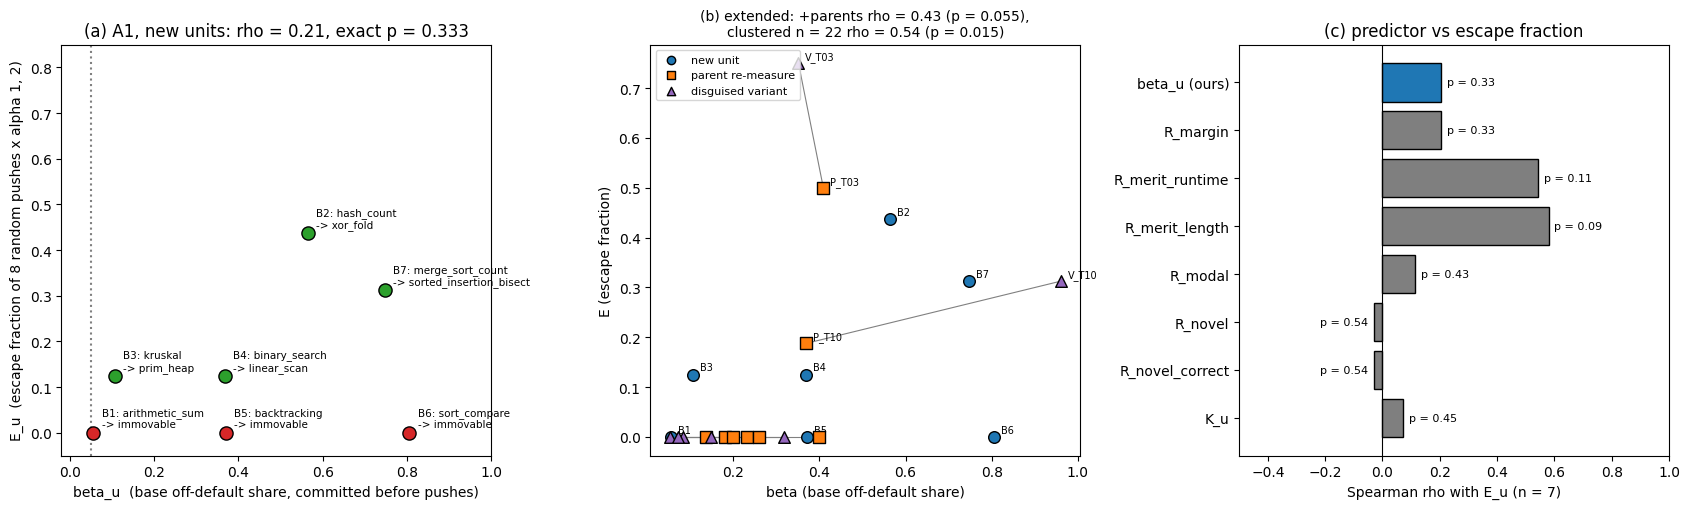

In [24]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
# (a) beta_u vs E_u, new units
ax = axs[0]
for x in _U:
    col = "tab:green" if x["E_u"] > 0 else "tab:red"
    ax.scatter(x["beta_u"], x["E_u"], s=90, color=col, edgecolor="k", zorder=3)
    ax.annotate(f"{x['unit']}: {x['default']}\n-> {x['push_landing'] or 'immovable'}", (x["beta_u"], x["E_u"]),
                textcoords="offset points", xytext=(6, 4), fontsize=7.5)
ax.set_xlabel("beta_u  (base off-default share, committed before pushes)")
ax.set_ylabel("E_u  (escape fraction of 8 random pushes x alpha 1, 2)")
ax.set_title(f"(a) A1, new units: rho = {_a1['primary']['rho']:.2f}, exact p = {_a1['primary']['p']:.3f}")
ax.axvline(0.05, ls=":", color="grey")
ax.set_xlim(-0.02, 1.0); ax.set_ylim(-0.05, 0.85)
# (b) extended view
ax = axs[1]
_vals = _ext["values"]
_mk = {"B": ("o", "tab:blue", "new unit"), "P": ("s", "tab:orange", "parent re-measure"), "V": ("^", "tab:purple", "disguised variant")}
for _t in sorted({u[2:] for u in _vals if u[:2] in ("P_", "V_")}):
    if f"P_{_t}" in _vals and f"V_{_t}" in _vals:
        ax.plot([_vals[f"P_{_t}"]["beta"], _vals[f"V_{_t}"]["beta"]], [_vals[f"P_{_t}"]["E"], _vals[f"V_{_t}"]["E"]],
                color="grey", lw=0.8, zorder=1)
for _u, _v in _vals.items():
    m, c, _ = _mk[_u[0]]
    ax.scatter(_v["beta"], _v["E"], marker=m, s=70, color=c, edgecolor="k", zorder=3)
    if _v["E"] > 0 or _u[0] == "B":
        ax.annotate(_u, (_v["beta"], _v["E"]), textcoords="offset points", xytext=(5, 3), fontsize=7)
for m, c, lab in _mk.values():
    ax.scatter([], [], marker=m, color=c, edgecolor="k", label=lab)
ax.legend(fontsize=8, loc="upper left")
ax.set_xlabel("beta (base off-default share)"); ax.set_ylabel("E (escape fraction)")
ax.set_title(f"(b) extended: +parents rho = {_ext['panel_plus_parents']['rho']:.2f} (p = {_ext['panel_plus_parents']['p']:.3f}),\n"
             f"clustered n = 22 rho = {_ext['clustered_all']['rho']:.2f} (p = {_ext['clustered_all']['p']:.3f})", fontsize=10)
# (c) rivals
ax = axs[2]
_names = ["beta_u (ours)"] + list(_a1["rivals"])
_rho = [_a1["primary"]["rho"]] + [r["rho_rival_E"] for r in _a1["rivals"].values()]
_p = [_a1["primary"]["p"]] + [r["p_rival"] for r in _a1["rivals"].values()]
ax.barh(_names[::-1], _rho[::-1], color=["tab:grey"] * (len(_names) - 1) + ["tab:blue"], edgecolor="k")
for i, (r, p) in enumerate(zip(_rho[::-1], _p[::-1])):
    ax.text(r + (0.02 if r >= 0 else -0.02), i, f"p = {p:.2f}", va="center", ha="left" if r >= 0 else "right", fontsize=8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlim(-0.5, 1.0)
ax.set_xlabel("Spearman rho with E_u (n = 7)")
ax.set_title("(c) predictor vs escape fraction")
plt.tight_layout()
plt.show()

**(d)** The per-direction escape map: stage-1 excess off-default share over the twin for each of the 8 isotropic directions at alpha = 1 and 2. ✓ marks a confirmed escape; ○ marks a cell that passed stage 1 but did not confirm. **(e)** A2: for each event, the push-landing composition (correct off-default programs pooled over confirmed escapes) next to the base model's non-default correct composition and the BASE / ASSOC / PROX forecasts. B7 had fewer than 20 correct base programs, so its BASE forecast is built from the attempt composition, which puts most of its mass on `other`.

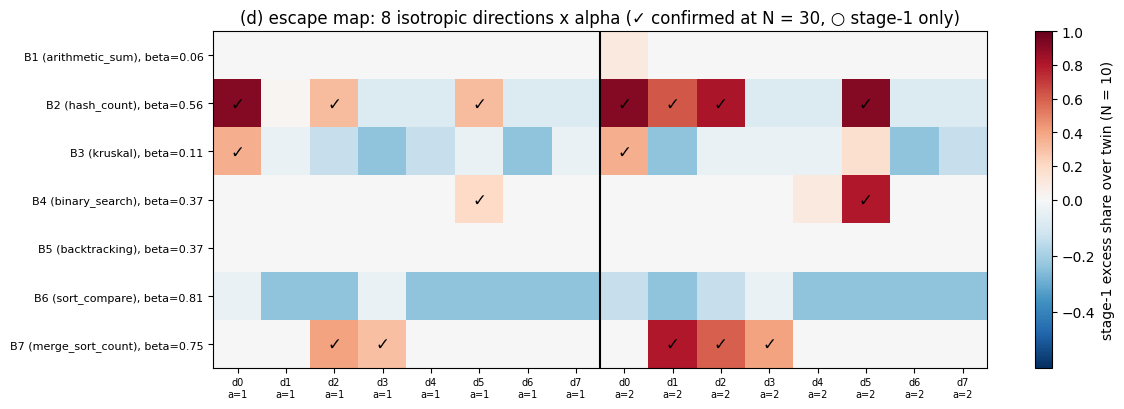

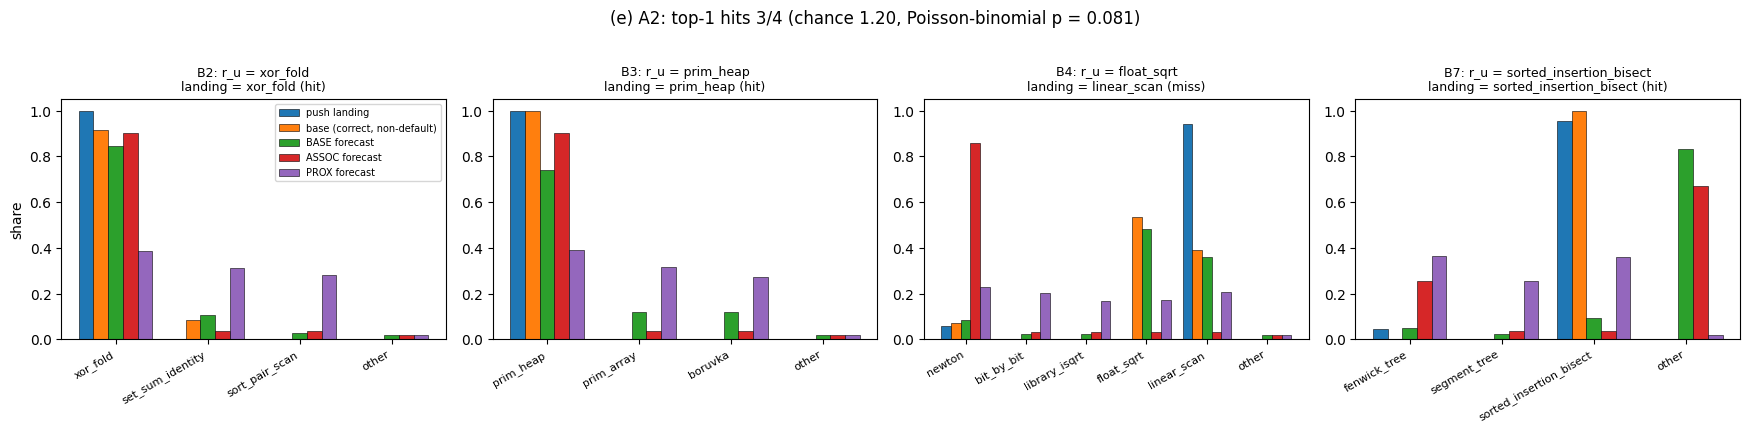

In [25]:
# (d) per-direction heatmap
_M = np.full((len(_U), 2 * N_DIRS), np.nan)
_txt = [["" for _ in range(2 * N_DIRS)] for _ in _U]
for i, x in enumerate(_U):
    for j, c in enumerate(x["per_direction"]):  # order: alpha 1 (8 seeds) then alpha 2 (8 seeds)
        _M[i, j] = c["excess_stage1"] if c["excess_stage1"] is not None else np.nan
        _txt[i][j] = "✓" if c["confirmed"] else ("○" if c["stage1_passed"] else "")
fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(_M, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-0.6, vcenter=0.0, vmax=1.0), aspect="auto")
for i in range(_M.shape[0]):
    for j in range(_M.shape[1]):
        if _txt[i][j]:
            ax.text(j, i, _txt[i][j], ha="center", va="center", fontsize=12, color="k")
ax.set_yticks(range(len(_U)), [f"{x['unit']} ({x['default']}), beta={x['beta_u']:.2f}" for x in _U], fontsize=8)
ax.set_xticks(range(2 * N_DIRS), [f"d{k}\na={a:g}" for a in ALPHAS for k in range(N_DIRS)], fontsize=7)
ax.axvline(N_DIRS - 0.5, color="k", lw=1.5)
plt.colorbar(im, ax=ax, label="stage-1 excess share over twin (N = 10)")
ax.set_title("(d) escape map: 8 isotropic directions x alpha (✓ confirmed at N = 30, ○ stage-1 only)")
plt.tight_layout()
plt.show()

# (e) A2 events: landing vs base composition and forecasts
_ev = _a2["events"]
_byu = {x["unit"]: x for x in _U}
fig, axs = plt.subplots(1, len(_ev), figsize=(4.4 * len(_ev), 4.2), squeeze=False)
for ax, e in zip(axs[0], _ev):
    x = _byu[e["unit"]]
    surv = [m for m in frozen_catalogue(e["unit"]) if m != x["default"]] + ["other"]
    comp = e["landing_composition"]; n_l = sum(comp.values())
    bc = {k: v for k, v in x["base_correct_composition"].items() if k != x["default"]}; n_b = sum(bc.values())
    series = {"push landing": [comp.get(m, 0) / n_l for m in surv],
              "base (correct, non-default)": [bc.get(m, 0) / n_b if n_b else 0 for m in surv],
              "BASE forecast": [x["forecasts"]["BASE"].get(m, 0) for m in surv],
              "ASSOC forecast": [x["forecasts"]["ASSOC"].get(m, 0) for m in surv],
              "PROX forecast": [x["forecasts"]["PROX"].get(m, 0) for m in surv]}
    w = 0.16
    for k, (lab, v) in enumerate(series.items()):
        ax.bar(np.arange(len(surv)) + (k - 2) * w, v, width=w, label=lab, edgecolor="k", lw=0.4)
    ax.set_xticks(range(len(surv)), surv, rotation=30, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{e['unit']}: r_u = {e['r_u']}\nlanding = {e['push_landing']} ({'hit' if e['hit'] else 'miss'})", fontsize=9)
axs[0][0].set_ylabel("share")
axs[0][0].legend(fontsize=7, loc="upper right")
fig.suptitle(f"(e) A2: top-1 hits {_a2['top1']['hits']:.0f}/{_a2['top1']['n']} (chance {_a2['top1']['expected_by_chance']:.2f}, "
             f"Poisson-binomial p = {_a2['top1']['poisson_binomial_p']:.3f})", y=1.02)
plt.tight_layout()
plt.show()

### 9d. Within-parent pairs

In [26]:
pd.DataFrame([{"parent": p["parent"], "default P / V": f"{p['default_parent']} / {p['default_variant']}",
               "beta P": p["beta_parent"], "beta V": p["beta_variant"], "E P": p["E_parent"], "E V": p["E_variant"],
               "McNemar (confirmed) P-only / V-only": f"{p['mcnemar_confirmed']['parent_only']} / "
                                                      f"{p['mcnemar_confirmed']['variant_only']}"}
              for p in _var["pairs"]]).round(3)

,parent,default P / V,beta P,beta V,E P,E V,McNemar (confirmed) P-only / V-only
0,T03,full_sort / full_sort,0.409,0.351,0.500,0.750,1 / 5
1,T10,union_find / bfs,0.368,0.960,0.188,0.312,2 / 4
2,T05,hash_map / hash_map,0.136,0.053,0.000,0.000,0 / 0
3,T06,hash_set / hash_set,0.200,0.318,0.000,0.000,0 / 0
4,T04,naive / naive,0.182,0.149,0.000,0.000,0 / 0
5,T08,iteration / iteration,0.400,0.071,0.000,0.000,0 / 0
6,T14,sort_by_count / NO_DEFAULT,0.259,NaN,0.000,0.000,0 / 0
7,R1,greedy_end / greedy_end,0.231,0.083,0.000,0.000,0 / 0


## Reading

**A1 (descriptive, n = 7).** Within panel B the primary statistic is weak and not significant: `beta_u` does not rank the escape fraction (rho = 0.21, exact one-sided p = 0.33). The units that moved (B2, B3, B4, B7) overlap in `beta_u` with those that did not (B1, B5, B6). Two clearly base-diverse units stayed immovable at alpha <= 2, most clearly **B6** (`beta_u` = 0.81, E = 0). That is the disconfirming pattern for the "diverse -> movable" half of the claim. All seven units were base-diverse (`beta_u` >= 0.05), so the "collapsed -> immovable" half is untested here. The graded plan-noise target agrees better (rho = 0.82, p = 0.017). The extended views that add the re-measured parents (rho = 0.43, p = 0.055, n = 15) and the variants (cluster-preserving rho = 0.54, p = 0.015, n = 22) are positive. None of these is the pre-registered primary test, and n is small. Among the rivals, R_merit (how much faster or shorter the best non-default reference is) correlates more strongly with E (rho 0.54-0.58) than `beta_u` does, and every CI is wide.

**A2 (4 events).** `r_u` named the push landing in 3 of 4 events (chance 1.2, Poisson-binomial p = 0.081). The base composition out-scored the association forecast by +0.68 nats per event and AST proximity by +0.13. With fewer than five events this stays descriptive. In this panel, what the base model writes is a better guide to *where* pushes land (suggestive, 4 events) than to *whether* a task moves.

**Within-parent.** Only T03 and T10 move, and T10's variant also shifts the twin default. The other six pairs stay at E = 0 under both wordings. Delta-beta does not track delta-E (Spearman 0.13, exact p = 0.5, n = 6).

These panel-B numbers are inputs to the pooled panel A + B test (`pooled_inputs.json` in the artifact), not a verdict on their own.

**Full run.** At the original config values this notebook reproduces every published number of the panel. To regenerate the labelled programs themselves, run `uv run method.py --stage all` in the artifact repository. That needs one 24 GB GPU, the two pinned Qwen3-8B snapshots and OpenRouter judge access; it took 1.74 GPU-hours and USD 0.19 of judge calls.